# Vorlesung 3 Statische Visualisierung

Eure Namen

- 1) Vorname Nachname
- 2) Vorname Nachname
- 3) ...

# Setup

In [ ]:
# Installation der benötigten Pakete
%pip install gapminder pandas plotnine

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Importiere benötigte Bibliotheken
import pandas as pd
from plotnine import *
from gapminder import gapminder # Datensatz mit Informationen zu Ländern, Kontinenten, Lebenserwartung, Bevölkerung und BIP pro Kopf
import numpy as np

c:\Users\Matthias\anaconda3\envs\geoenv\Lib\site-packages\gapminder\data.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.


# Gapminder - EDA (Explorative Daten Analyse) 

In [3]:
# Zeige die Form des Gapminder-Datensatzes
print(gapminder.shape) #Länge und Breite des Datensatzes

# Zeige die Spaltennamen des Gapminder-Datensatzes
print(gapminder.columns) #Spaltennamen des Datensatzes

# Zeige die ersten Zeilen des Gapminder-Datensatzes
print(gapminder.head()) #die ersten 5 Zeilen des Datensatzes

# Daten für Deutschland filtern
germany_data = gapminder[gapminder['country'] == 'Germany']
print(germany_data.tail()) #die letzten 5 Zeilen des Datensatzes für Deutschland

(1704, 6)
Index(['country', 'continent', 'year', 'lifeExp', 'pop', 'gdpPercap'], dtype='object')
       country continent  year  lifeExp       pop   gdpPercap
0  Afghanistan      Asia  1952   28.801   8425333  779.445314
1  Afghanistan      Asia  1957   30.332   9240934  820.853030
2  Afghanistan      Asia  1962   31.997  10267083  853.100710
3  Afghanistan      Asia  1967   34.020  11537966  836.197138
4  Afghanistan      Asia  1972   36.088  13079460  739.981106
     country continent  year  lifeExp       pop    gdpPercap
571  Germany    Europe  1987   74.847  77718298  24639.18566
572  Germany    Europe  1992   76.070  80597764  26505.30317
573  Germany    Europe  1997   77.340  82011073  27788.88416
574  Germany    Europe  2002   78.670  82350671  30035.80198
575  Germany    Europe  2007   79.406  82400996  32170.37442


In [4]:
# Beschreibe die Daten
print(gapminder.describe()) # Beschreibe den Gapminder-Datensatz

# Deutschland Daten beschreiben
print(germany_data.describe()) # Beschreibe den Datensatz für Deutschland

             year      lifeExp           pop      gdpPercap
count  1704.00000  1704.000000  1.704000e+03    1704.000000
mean   1979.50000    59.474439  2.960121e+07    7215.327081
std      17.26533    12.917107  1.061579e+08    9857.454543
min    1952.00000    23.599000  6.001100e+04     241.165876
25%    1965.75000    48.198000  2.793664e+06    1202.060309
50%    1979.50000    60.712500  7.023596e+06    3531.846988
75%    1993.25000    70.845500  1.958522e+07    9325.462346
max    2007.00000    82.603000  1.318683e+09  113523.132900
              year    lifeExp           pop     gdpPercap
count    12.000000  12.000000  1.200000e+01     12.000000
mean   1979.500000  73.444417  7.754704e+07  20556.684433
std      18.027756   3.872603  4.341644e+06   8076.261913
min    1952.000000  67.500000  6.914595e+07   7144.114393
25%    1965.750000  70.675000  7.571112e+07  14284.834935
50%    1979.500000  73.150000  7.824802e+07  21272.226985
75%    1993.250000  76.387500  8.095109e+07  26826.198

In [5]:
# Filter für 1952 und 2007 erstellen
gm_1952 = gapminder[gapminder['year'] == 1952].copy()
gm_2007 = gapminder[gapminder['year'] == 2007].copy()

# Korrelationsmatrizen (nur numerische Variablen) berechnen
corr_1952 = gm_1952[['lifeExp', 'pop', 'gdpPercap']].corr()
corr_2007 = gm_2007[['lifeExp', 'pop', 'gdpPercap']].corr()

# Ausgabe der Korrelationsmatrizen
print("=== Correlation Matrix – 1952 ===")
print(corr_1952.round(3))
print("\n=== Correlation Matrix – 2007 ===")
print(corr_2007.round(3))

=== Correlation Matrix – 1952 ===
           lifeExp    pop  gdpPercap
lifeExp      1.000 -0.003      0.278
pop         -0.003  1.000     -0.025
gdpPercap    0.278 -0.025      1.000

=== Correlation Matrix – 2007 ===
           lifeExp    pop  gdpPercap
lifeExp      1.000  0.048      0.679
pop          0.048  1.000     -0.056
gdpPercap    0.679 -0.056      1.000


In [6]:
#  Datenvorbereitung für Korrelationsmatrix 1952 vs. 2007
gm_1952 = gapminder[gapminder['year'] == 1952][['lifeExp', 'pop', 'gdpPercap']].corr().reset_index().melt(id_vars='index')
gm_1952['year'] = '1952'

gm_2007 = gapminder[gapminder['year'] == 2007][['lifeExp', 'pop', 'gdpPercap']].corr().reset_index().melt(id_vars='index')
gm_2007['year'] = '2007'

# Kombinieren der beiden DataFrames
corr_df = pd.concat([gm_1952, gm_2007])
corr_df.columns = ['var1', 'var2', 'correlation', 'year']

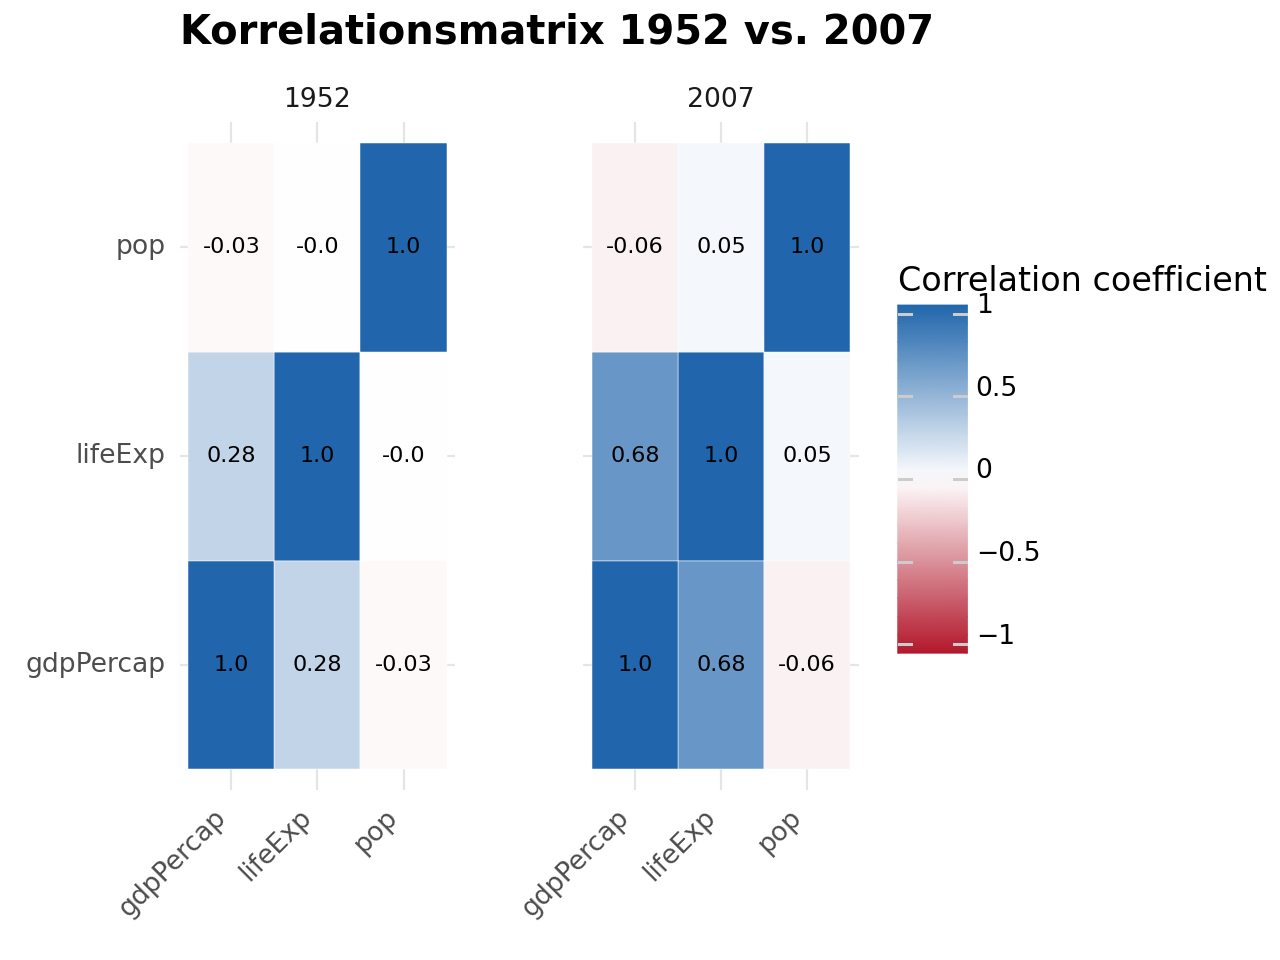

<Figure Size: (640 x 480)>

In [7]:
# Korrelationsplot/matrix mit plotnine erstellen
(
    ggplot(corr_df, aes(x='var1', y='var2', fill='correlation')) +
    geom_tile(color='white') +
    facet_wrap('~year') +
    geom_text(aes(label='round(correlation,2)'), color='black', size=8) +
    scale_fill_gradient2(low='#b2182b', mid='white', high='#2166ac', limits=(-1,1)) +
    labs(
        title='Korrelationsmatrix 1952 vs. 2007',
        subtitle='',
        x='', y='', fill='Correlation coefficient'
    ) +
    theme_minimal(base_size=12) +
    theme(
        axis_text_x=element_text(rotation=45, ha='right'),
        panel_spacing_x=0.1,
        plot_title=element_text(weight='bold')
    )
)

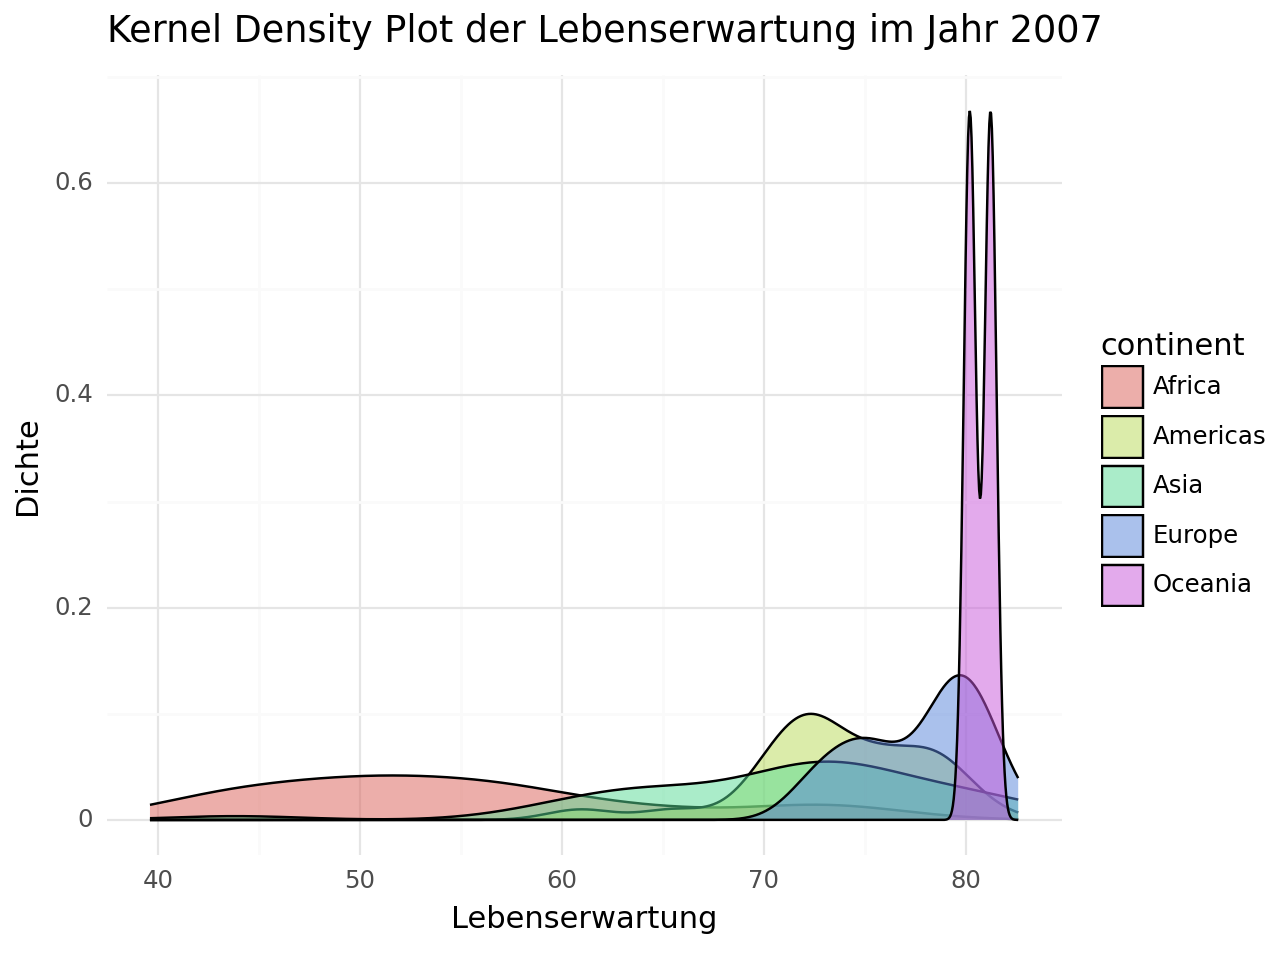

<Figure Size: (640 x 480)>

In [8]:
# Kernel density plot 2007 für Lebenserwartung
data_2007 = gapminder[gapminder['year'] == 2007]
(
    ggplot(data_2007, aes(x='lifeExp', fill='continent')) +
    geom_density(alpha=0.5) +
    labs(title='Kernel Density Plot der Lebenserwartung im Jahr 2007',
         x='Lebenserwartung',
         y='Dichte') +
    theme_minimal()
)

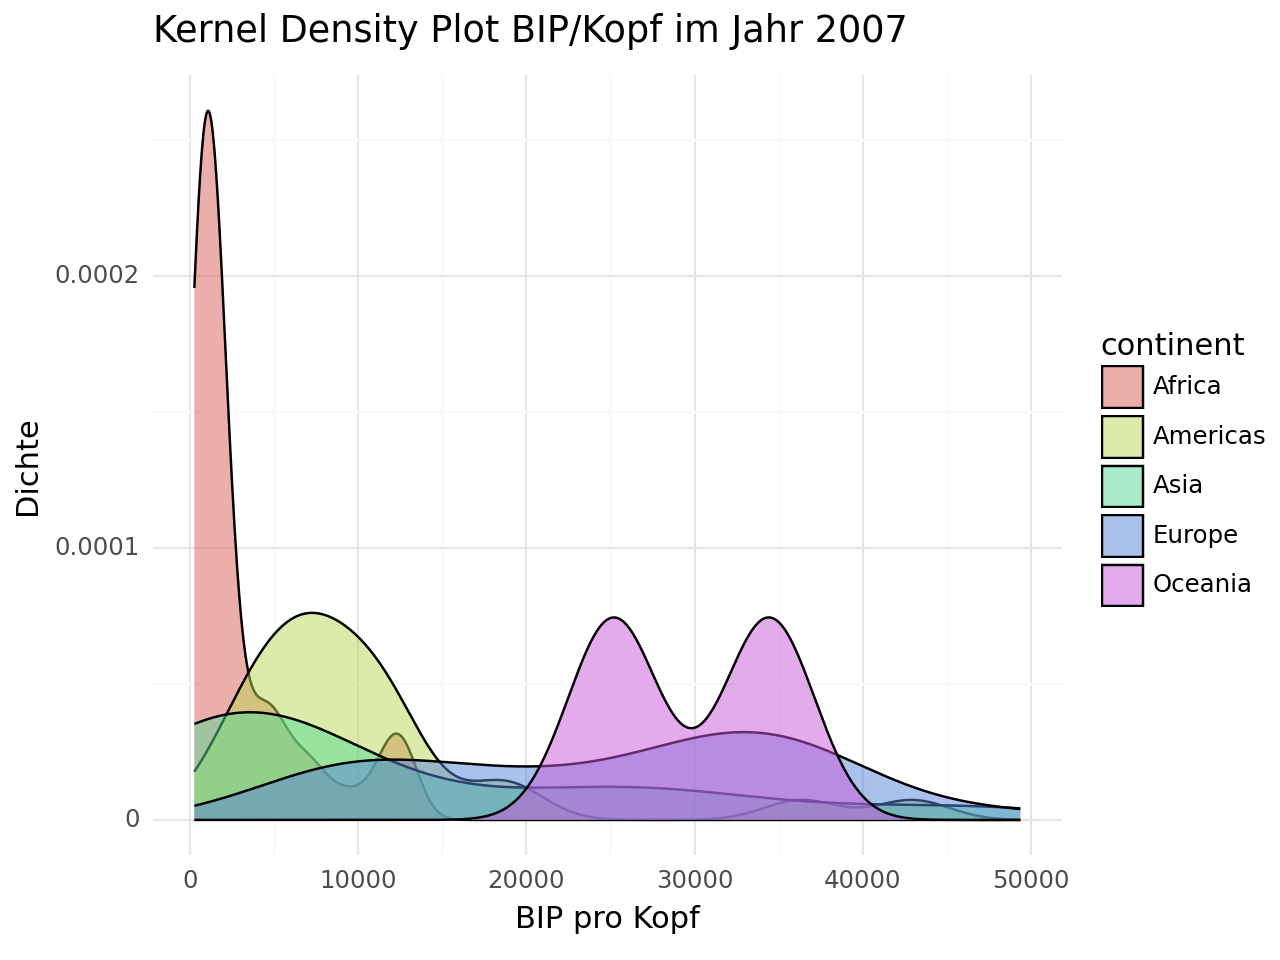

<Figure Size: (640 x 480)>

In [9]:
# Kernel density plot 2007 für gdpPercap
data_2007 = gapminder[gapminder['year'] == 2007]
(
    ggplot(data_2007, aes(x='gdpPercap', fill='continent')) +
    geom_density(alpha=0.5) +
    labs(title='Kernel Density Plot BIP/Kopf im Jahr 2007',
         x='BIP pro Kopf',
         y='Dichte') +
    theme_minimal()
)

c:\Users\Matthias\anaconda3\envs\geoenv\Lib\site-packages\plotnine\stats\stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 8'. Pick better value with 'binwidth'.


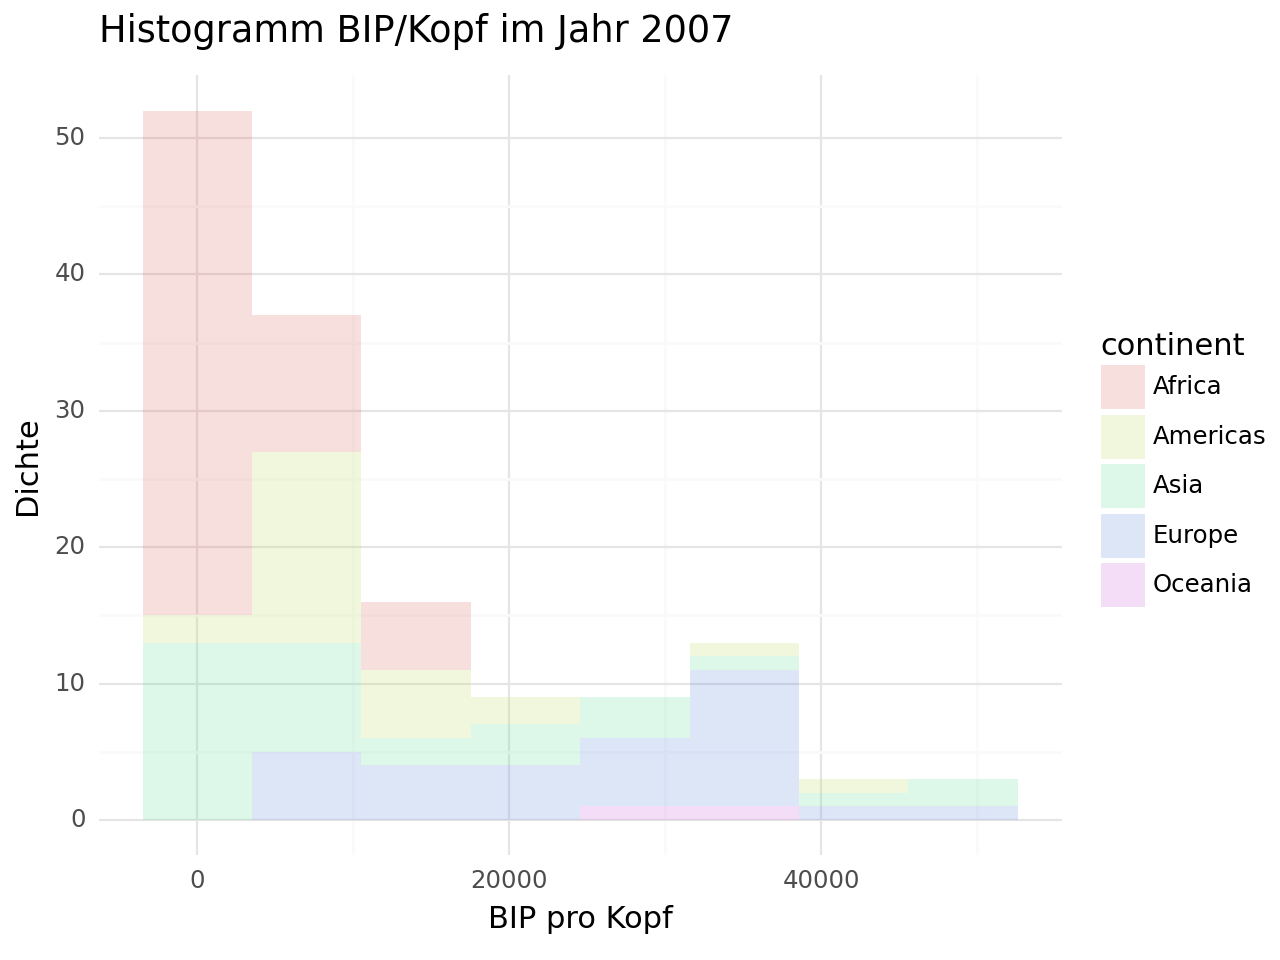

<Figure Size: (640 x 480)>

In [10]:
# histogram 2007 für gdpPercap
data_2007 = gapminder[gapminder['year'] == 2007]
(
    ggplot(data_2007, aes(x='gdpPercap', fill='continent')) +
    geom_histogram(alpha=0.2) +
    labs(title='Histogramm BIP/Kopf im Jahr 2007',
         x='BIP pro Kopf',
         y='Dichte') +
    theme_minimal()
)

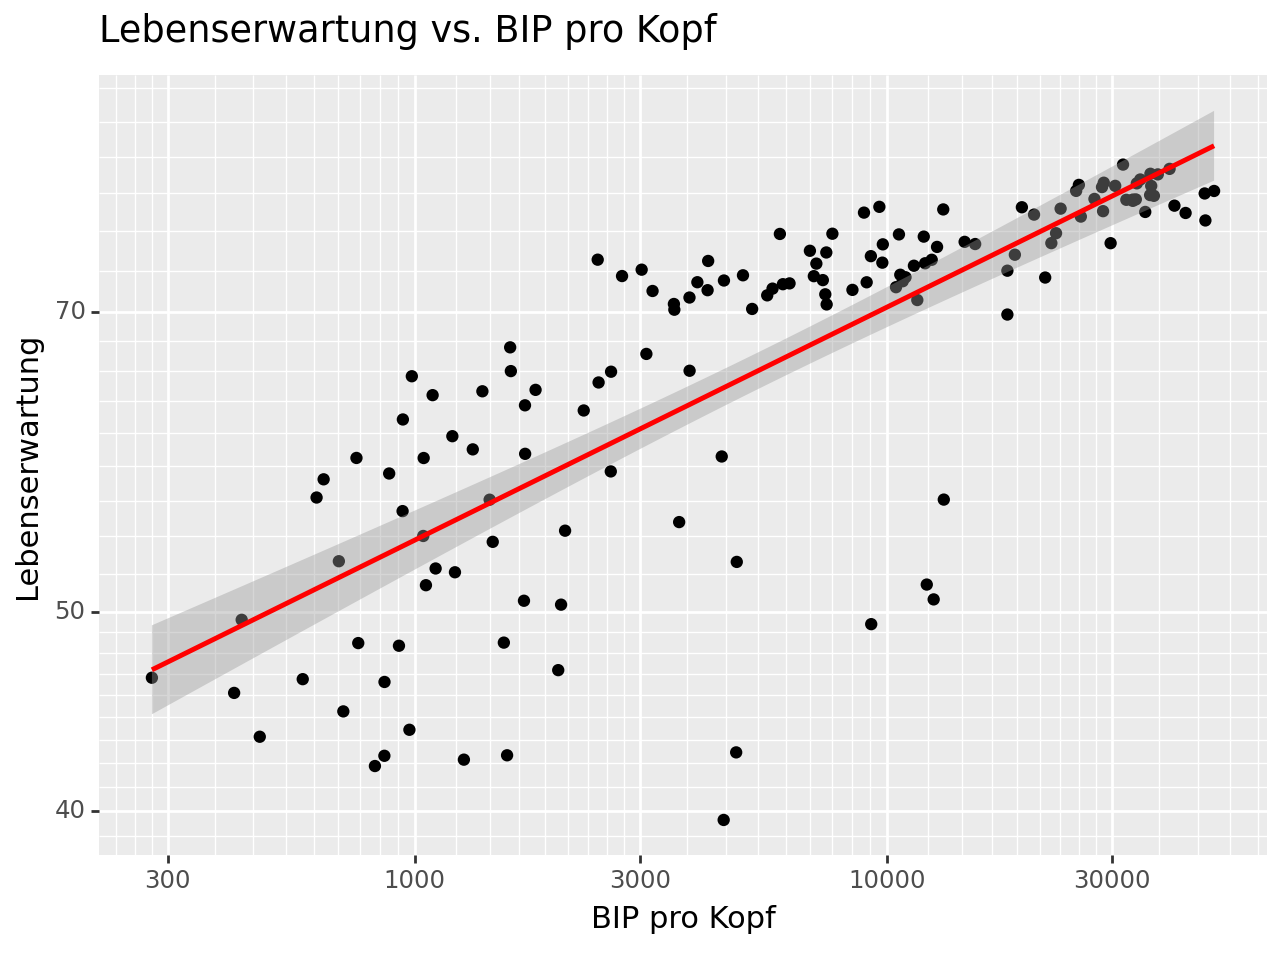

<Figure Size: (640 x 480)>

In [11]:
# Scatterplot Lebenserwartung vs. BIP pro Kopf 2007
(ggplot(data_2007, aes(x='gdpPercap', y='lifeExp'))
 + geom_point()
 + geom_smooth(method='lm', color='red')
 + scale_x_log10()
 + scale_y_log10()
 + labs(title='Lebenserwartung vs. BIP pro Kopf',
        x='BIP pro Kopf',
        y='Lebenserwartung')
        )


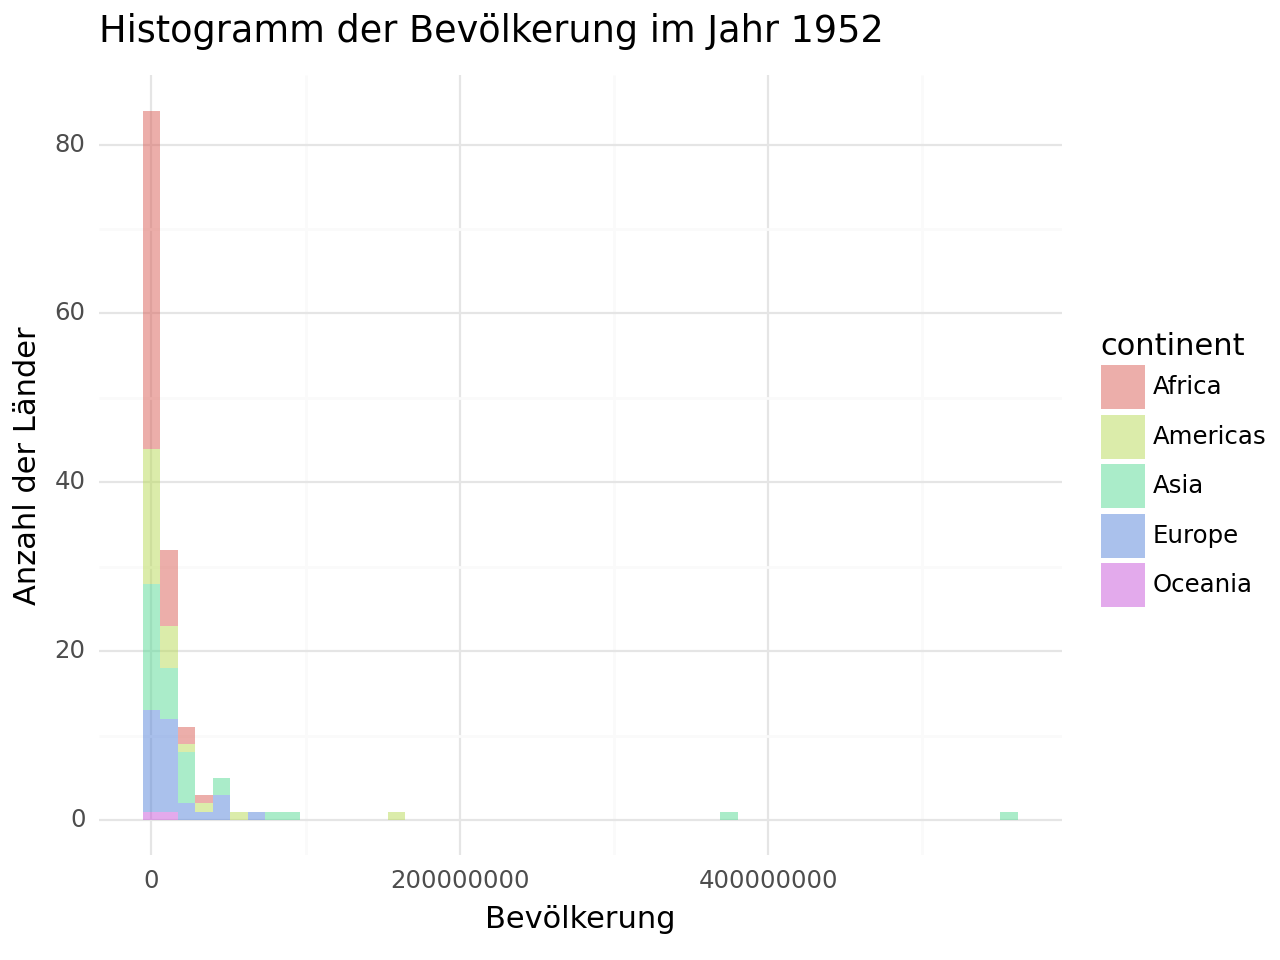

<Figure Size: (640 x 480)>

In [12]:
# Histogramm für die Bevölkerung im Jahr 1952
data_1952 = gapminder[gapminder['year'] == 1952]

(
    ggplot(data_1952, aes(x='pop', fill='continent')) +
    geom_histogram(alpha=0.5, bins=50) +
    labs(
        title='Histogramm der Bevölkerung im Jahr 1952',
        x='Bevölkerung',
        y='Anzahl der Länder'
    ) +
    theme_minimal()
)

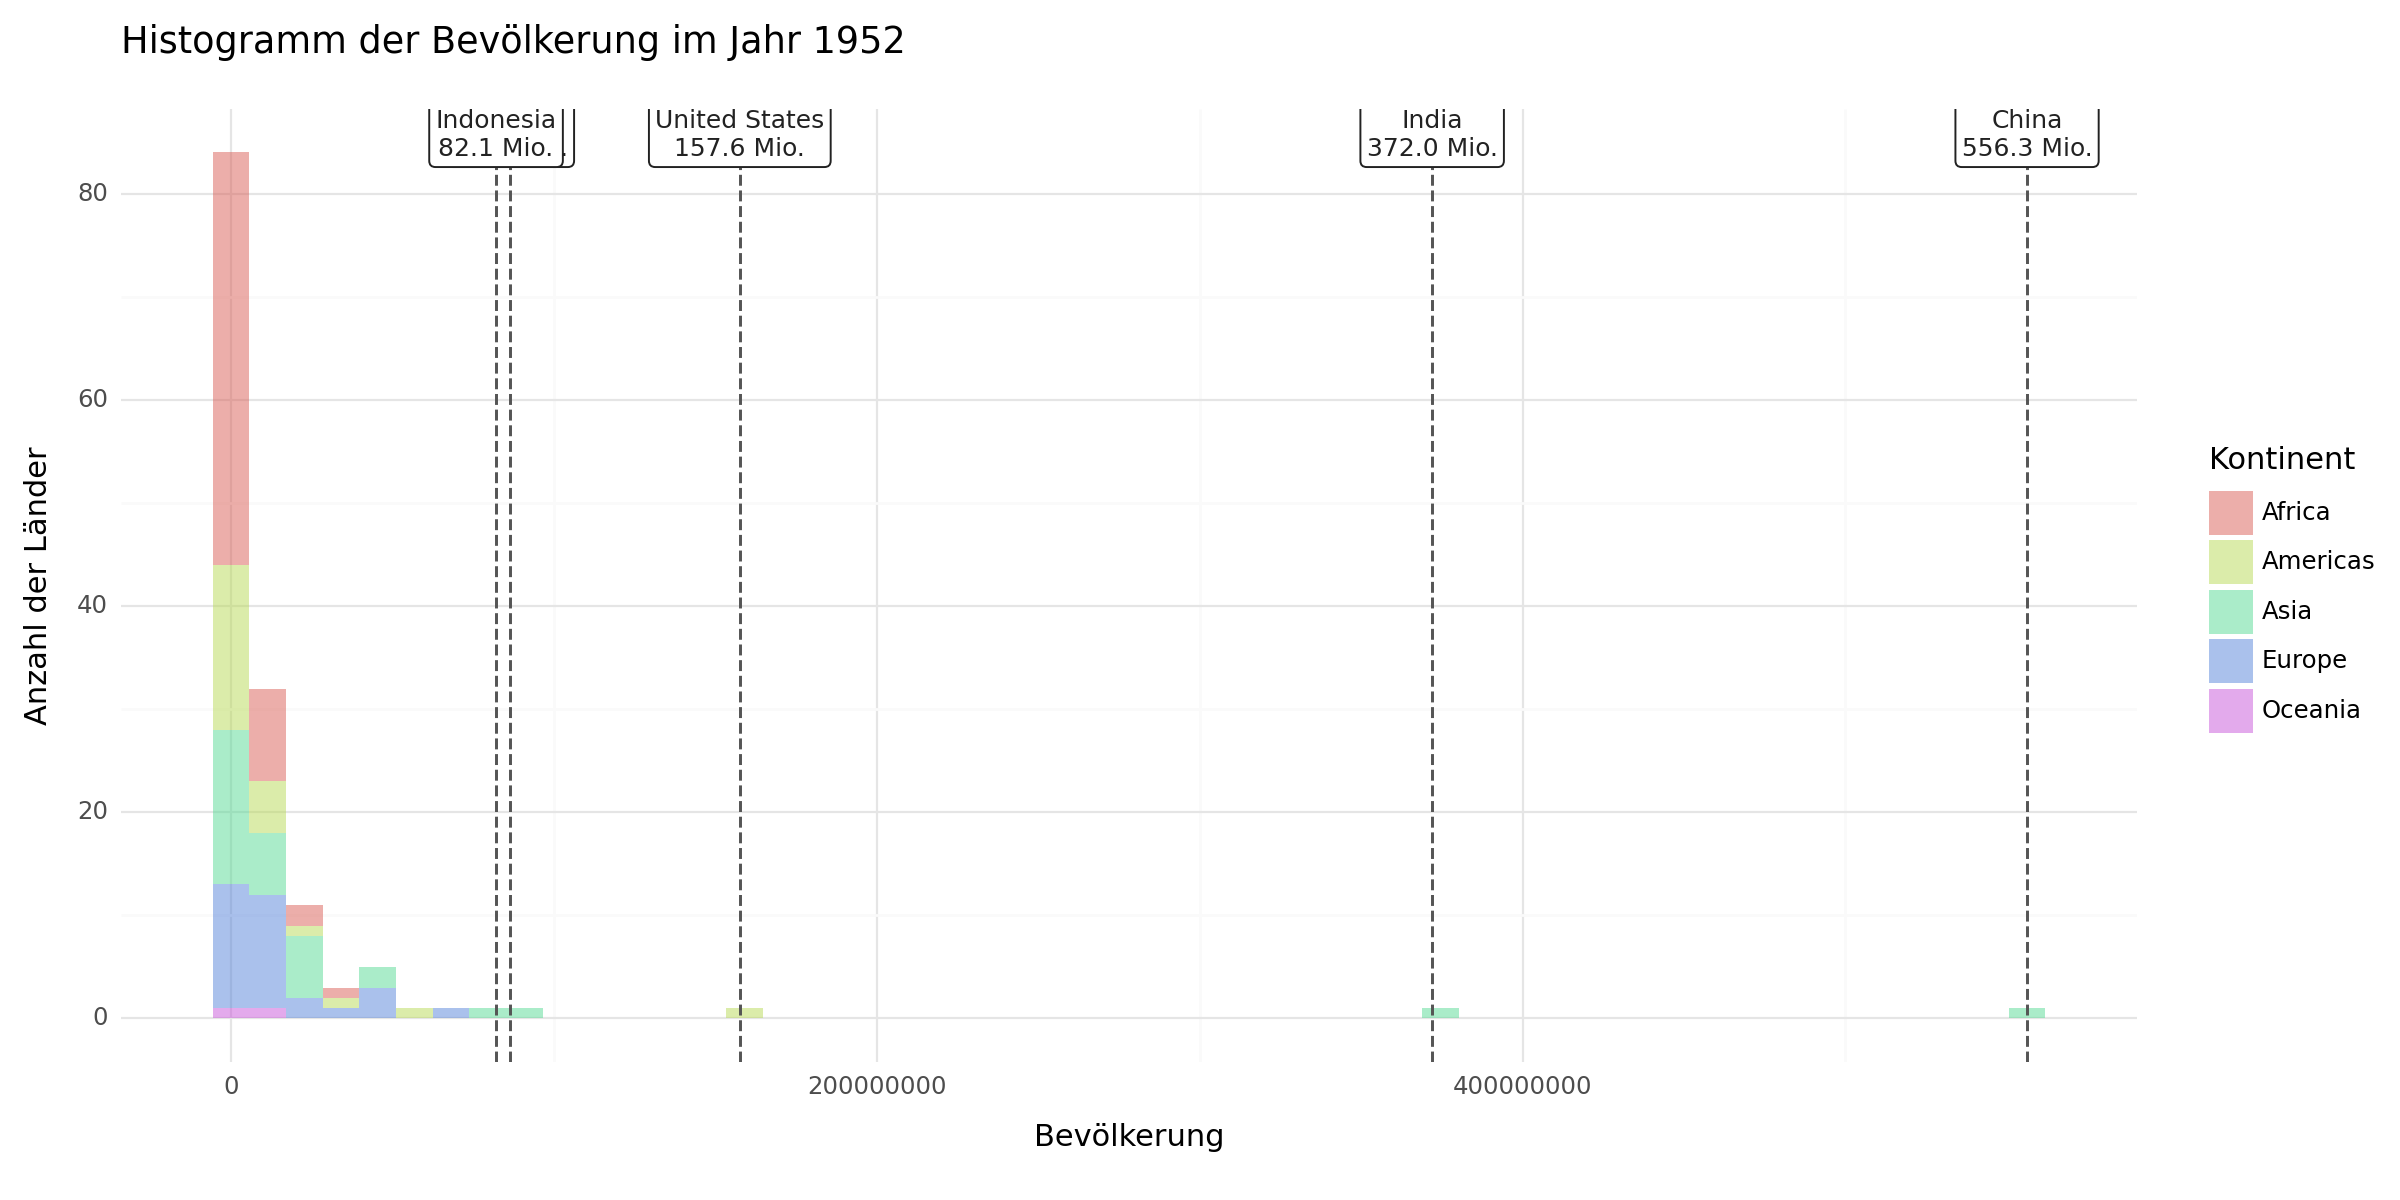

<Figure Size: (1200 x 600)>

In [13]:
# Imports
from plotnine import (
    ggplot, aes, geom_histogram, geom_vline, geom_label,
    labs, theme_minimal, theme
)

# Bevölkerung im Jahr 1952
data_1952 = gapminder.loc[gapminder["year"] == 1952].copy()

# Fünf bevölkerungsreichste Länder
top_5 = data_1952.nlargest(5, "pop").copy()
top_5["label"] = top_5.apply(
    lambda row: f"{row['country']}\n{row['pop'] / 1e6:.1f} Mio.",
    axis=1,
)

plot = (
    ggplot(data_1952, aes(x="pop", fill="continent"))
    + geom_histogram(alpha=0.5, bins=50)
    + geom_vline(
        data=top_5,
        mapping=aes(xintercept="pop"),
        inherit_aes=False,
        linetype="dashed",
        color="#555555",
        size=0.6,
    )
    + geom_label(
        data=top_5,
        mapping=aes(x="pop", label="label"),
        y=float("inf"),
        inherit_aes=False,
        va="top",
        ha="center",
        size=9,
        fill="white",
        color="#222222",
    )
    + labs(
        title="Histogramm der Bevölkerung im Jahr 1952",
        x="Bevölkerung",
        y="Anzahl der Länder",
        fill="Kontinent",
    )
    + theme_minimal()
    + theme(figure_size=(12, 6))
)

display(plot)

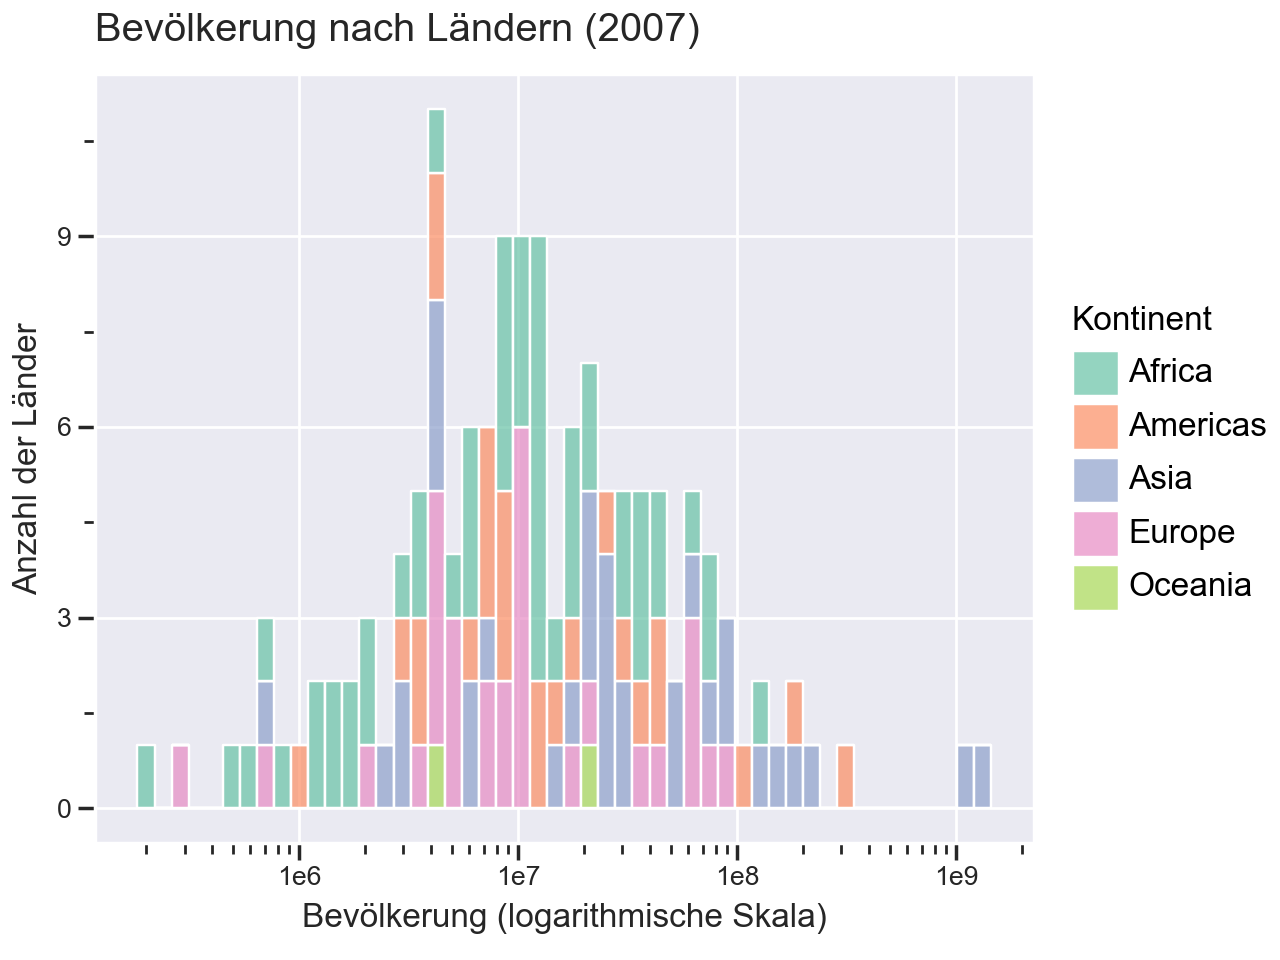

<Figure Size: (640 x 480)>

In [14]:
# Histogramm für die Bevölkerung im Jahr 2007 im logarithmischen Maßstab 
# in Python Seaborn Style

(
    ggplot(data_2007, aes(x='pop', fill='continent')) +
    geom_histogram(alpha=0.7, bins=50, color='white') +
    scale_x_log10() +
    scale_fill_brewer(type='qual', palette='Set2') +
    labs(
        title='Bevölkerung nach Ländern (2007)',
        x='Bevölkerung (logarithmische Skala)',
        y='Anzahl der Länder',
        fill='Kontinent'
    ) +
    theme_seaborn()
)

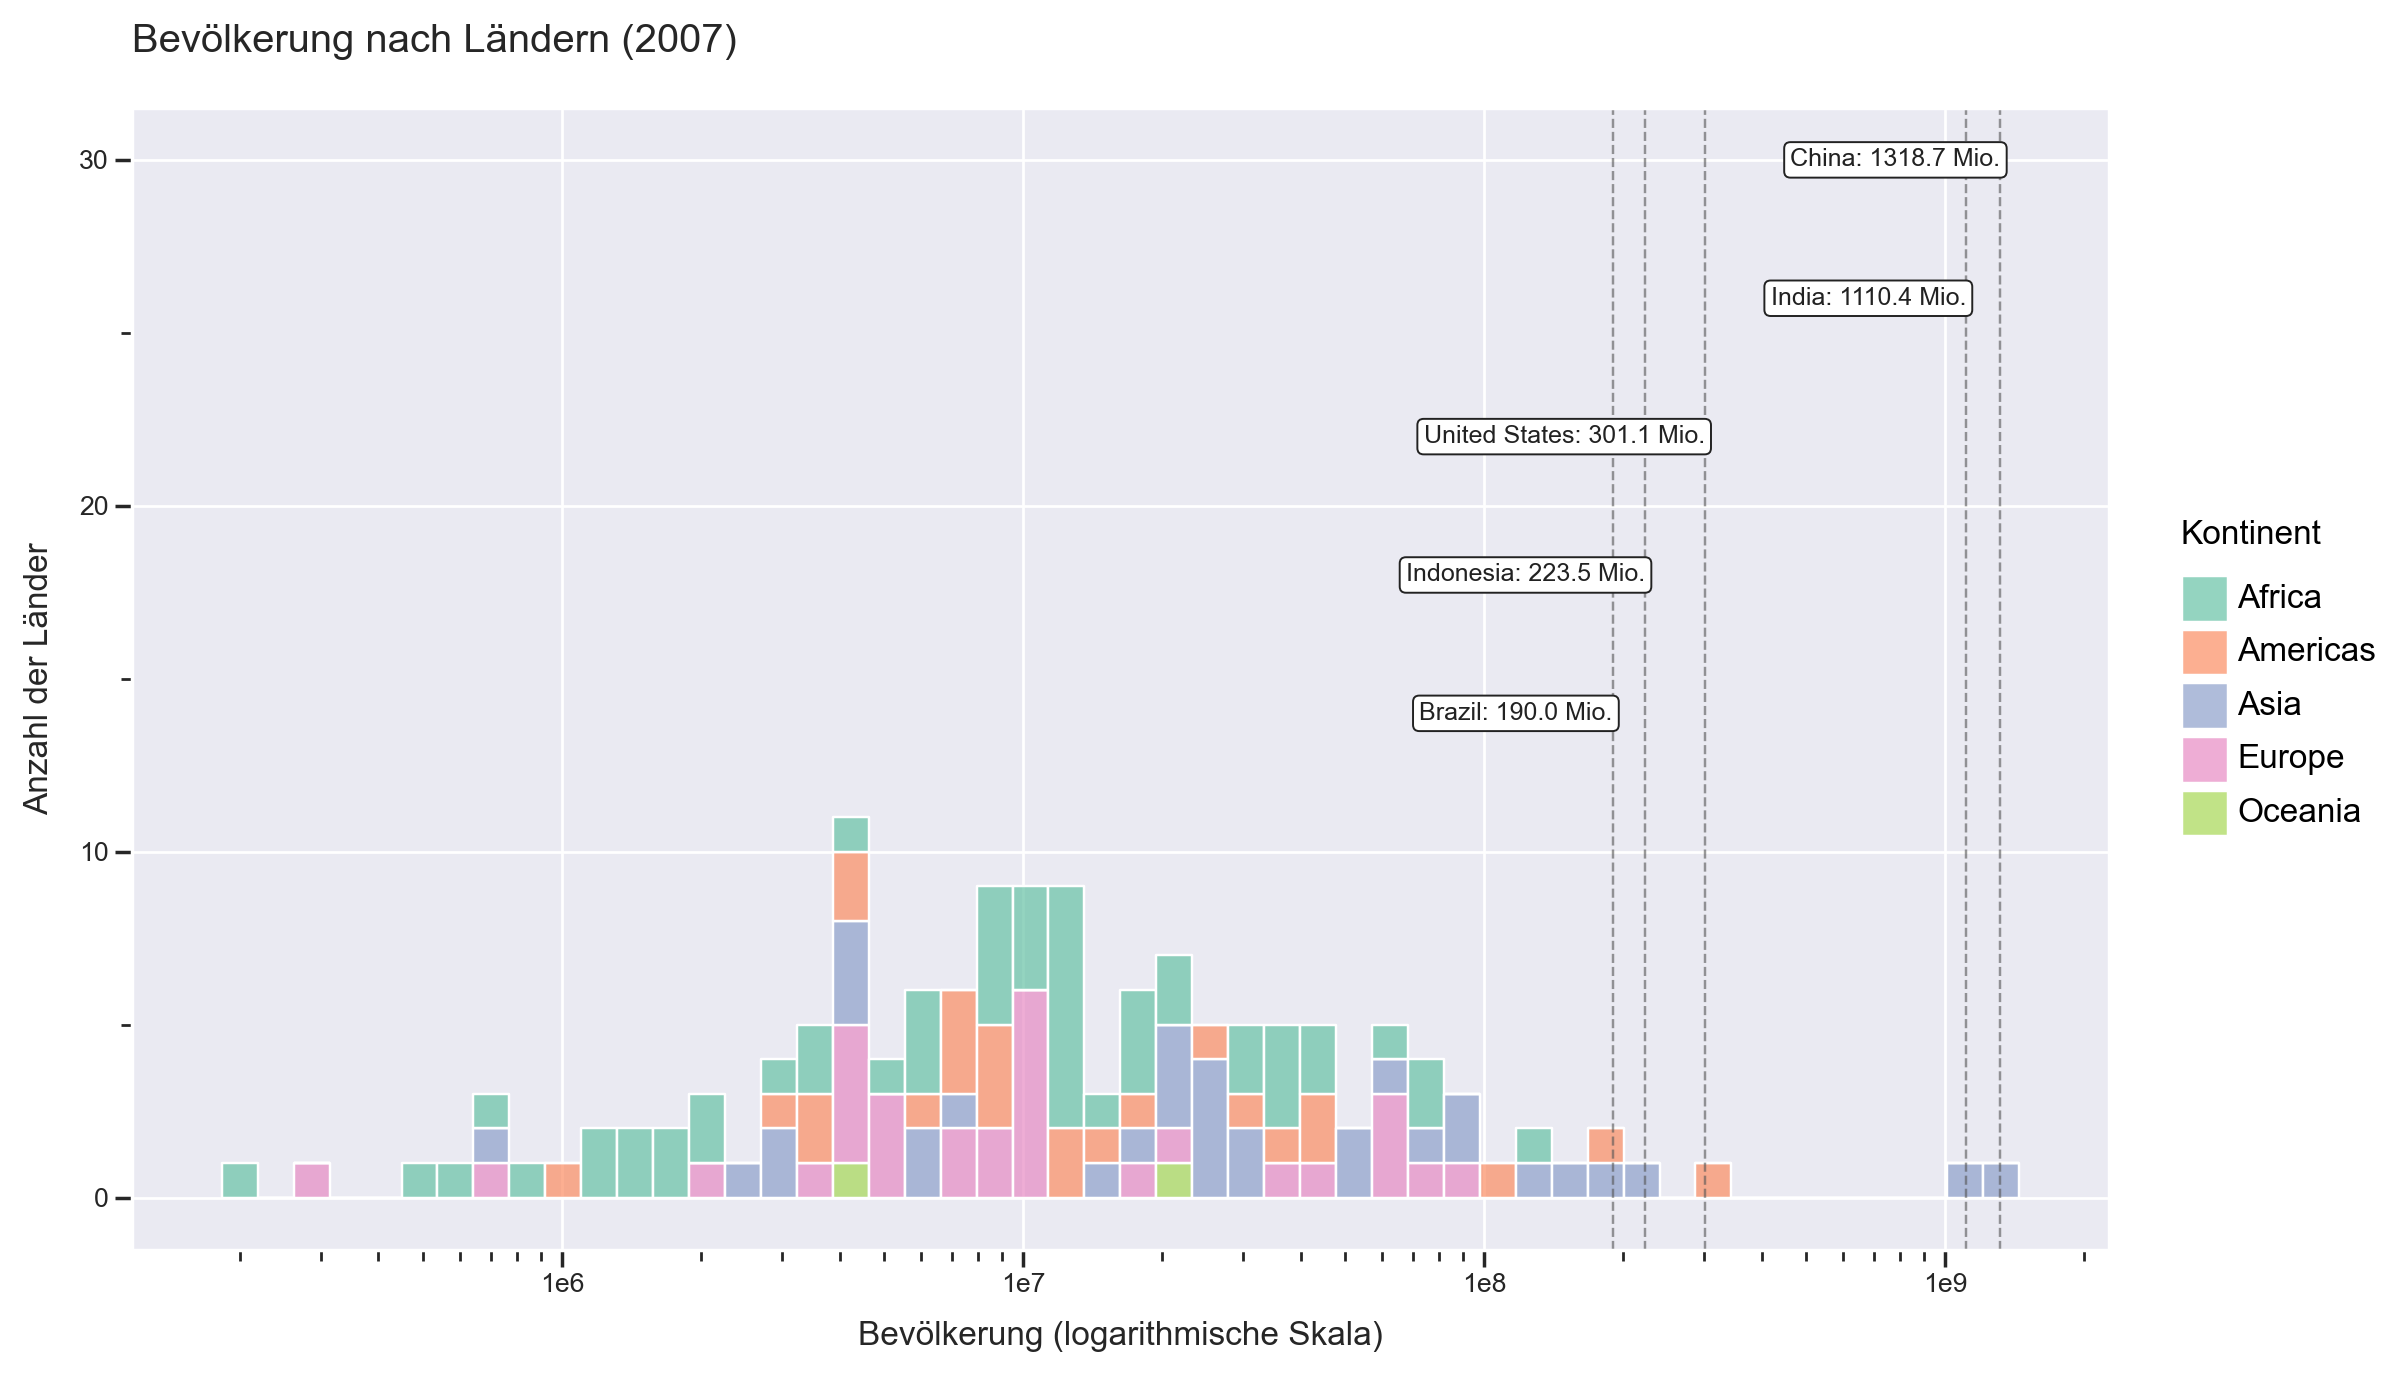

<Figure Size: (1200 x 700)>

In [15]:
from plotnine import (
    ggplot, aes, geom_histogram, geom_vline, geom_label,
    scale_x_log10, scale_fill_brewer, labs, theme_seaborn, theme
)

data_2007 = gapminder.loc[gapminder["year"] == 2007].copy()

# Die fünf bevölkerungsreichsten Länder
top_5 = data_2007.nlargest(5, "pop").copy()
top_5["label"] = top_5.apply(
    lambda row: f"{row['country']}: {row['pop'] / 1e6:.1f} Mio.",
    axis=1,
)

# Beschriftungen von oben nach unten staffeln
top_5["label_y"] = [30, 26, 22, 18, 14]

plot = (
    ggplot(data_2007, aes(x="pop", fill="continent"))
    + geom_histogram(alpha=0.7, bins=50, color="white")
    + geom_vline(
        data=top_5,
        mapping=aes(xintercept="pop"),
        inherit_aes=False,
        linetype="dashed",
        color="#555555",
        size=0.5,
        alpha=0.6,
    )
    + geom_label(
        data=top_5,
        mapping=aes(x="pop", y="label_y", label="label"),
        inherit_aes=False,
        ha="right",
        size=9,
        fill="white",
        color="#222222",
    )
    + scale_x_log10()
    + scale_fill_brewer(type="qual", palette="Set2")
    + labs(
        title="Bevölkerung nach Ländern (2007)",
        x="Bevölkerung (logarithmische Skala)",
        y="Anzahl der Länder",
        fill="Kontinent",
    )
    + theme_seaborn()
    + theme(figure_size=(12, 7))
)

display(plot)

# Aufgabe 1

Frage: Wie hängen Einkommen und Lebenserwartung zusammen?
Ziel: Verständnis von Aesthetic Mapping und Scale Transformation (lineare und log Skala)

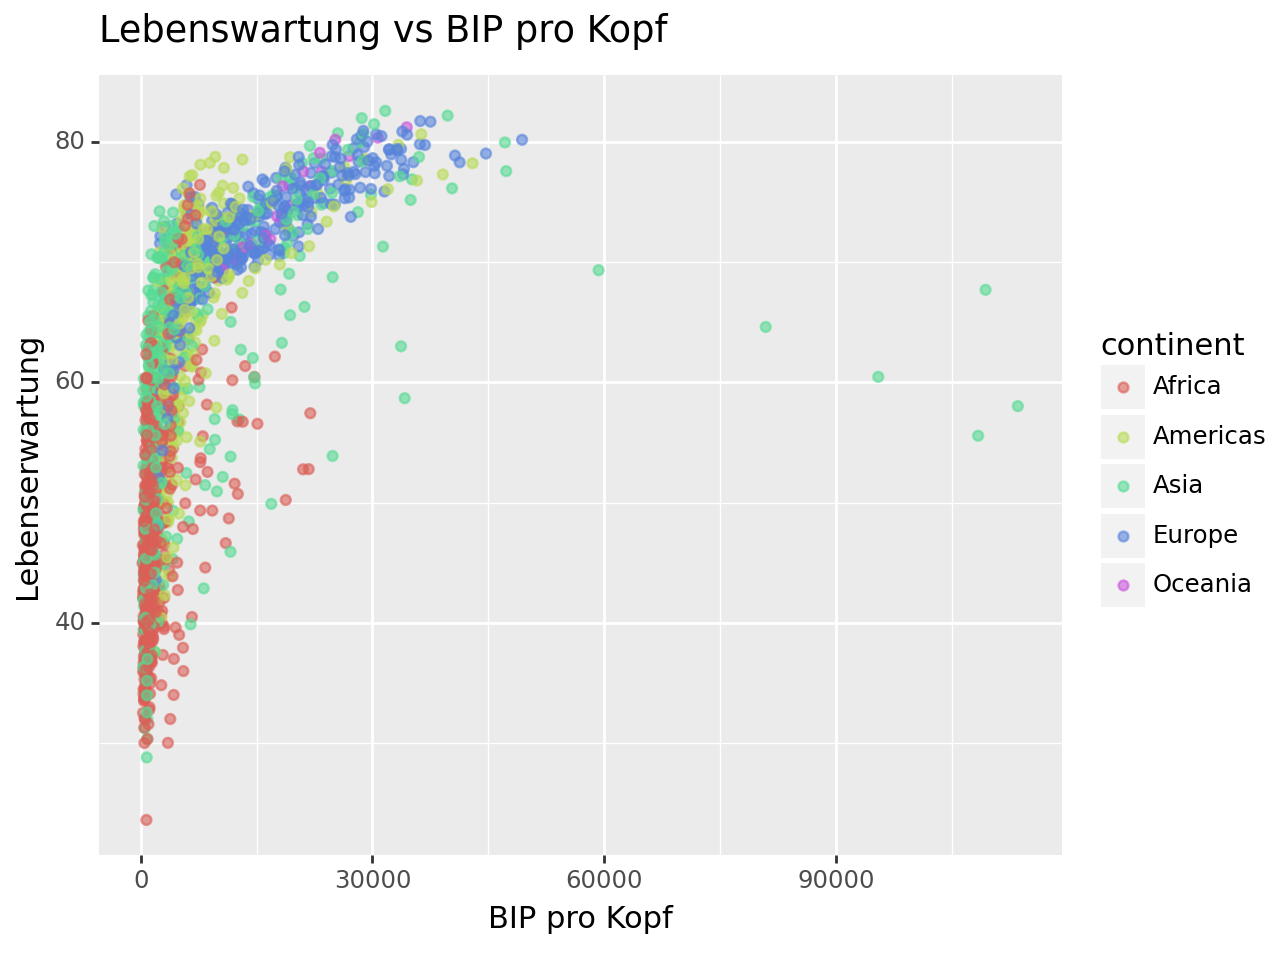

<Figure Size: (640 x 480)>

In [29]:
# Lineare Skala (x-Achse)
(ggplot(gapminder, aes(x='gdpPercap', y='lifeExp', color='continent'))
 + geom_point(alpha=0.6)
 + labs(title='Lebenswartung vs BIP pro Kopf',
        x='BIP pro Kopf',
        y='Lebenserwartung'))


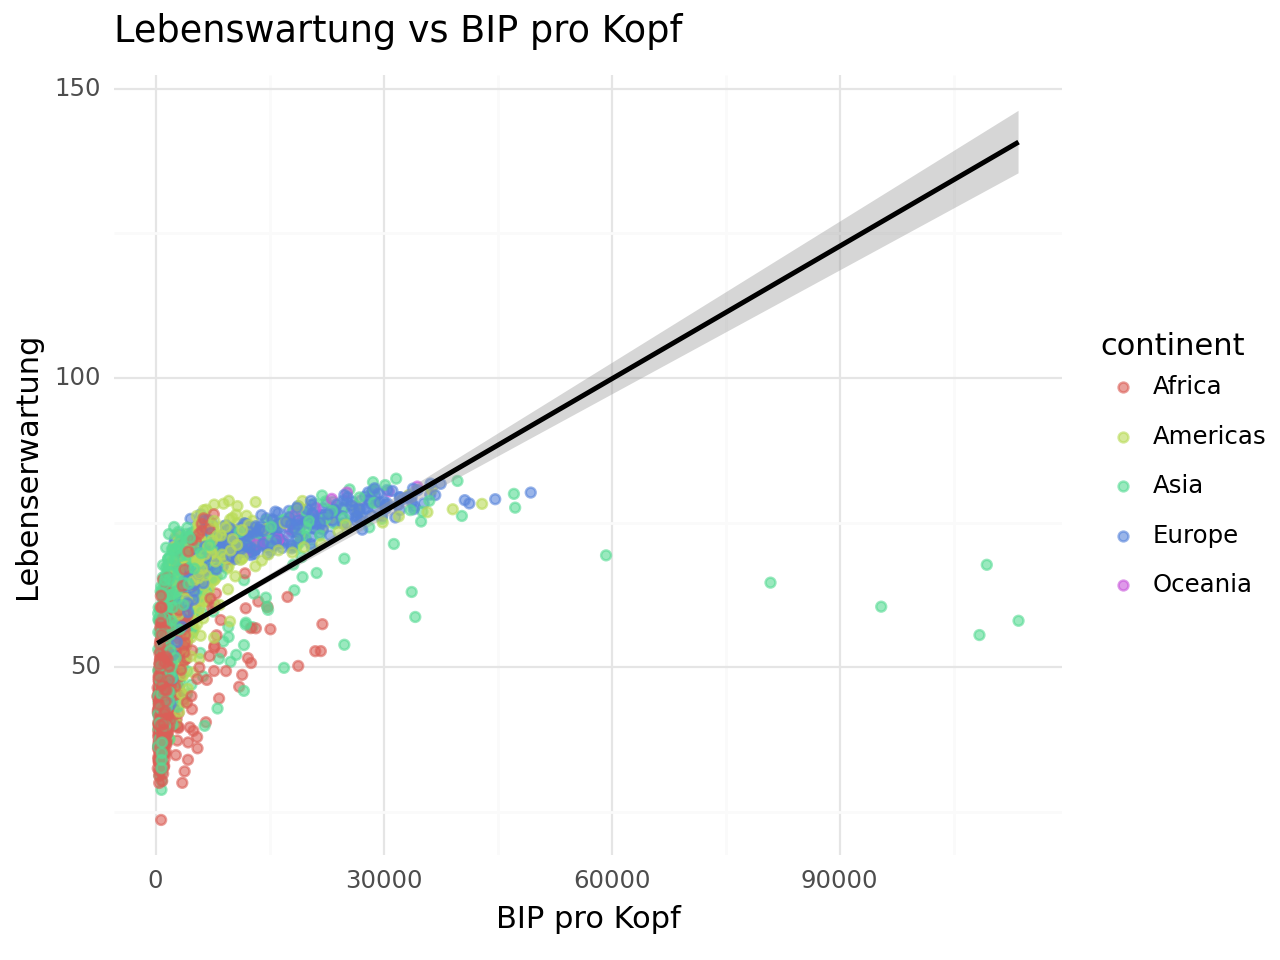

<Figure Size: (640 x 480)>

In [28]:
# Lineare Skala (x-Achse)
(ggplot(gapminder, aes(x='gdpPercap', y='lifeExp', color='continent'))
 + geom_point(alpha=0.6)
 + theme_minimal()
 + geom_smooth(method='lm', color='black')
 + labs(title='Lebenswartung vs BIP pro Kopf',
        x='BIP pro Kopf',
        y='Lebenserwartung'))


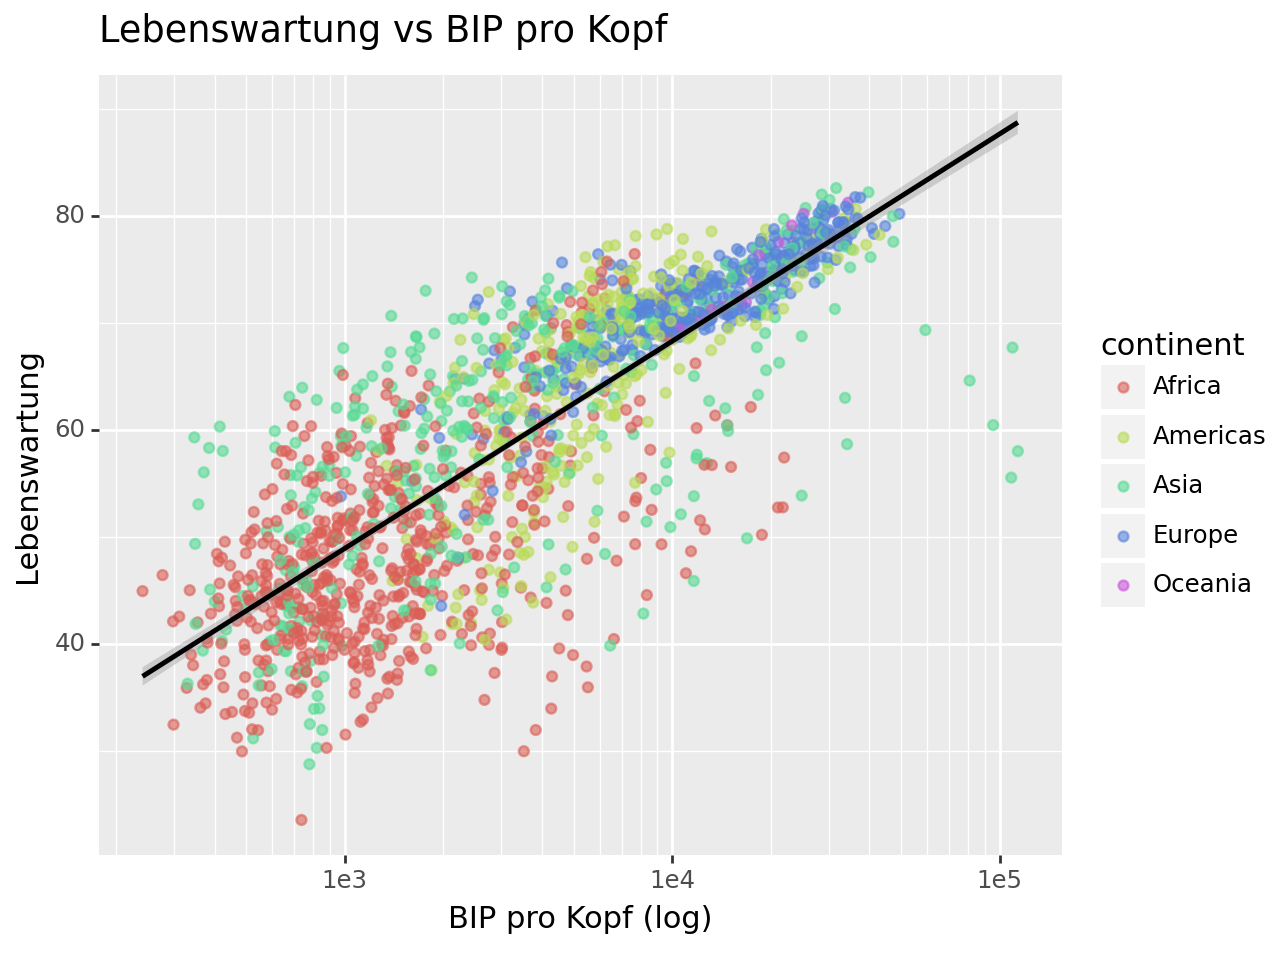

<Figure Size: (640 x 480)>

In [31]:
# Logarithmische Skala (x-Achse)
(ggplot(gapminder, aes(x='gdpPercap', y='lifeExp', color='continent'))
 + geom_point(alpha=0.6)
 + scale_x_log10()
 + geom_smooth(method='lm', color='black')
 + labs(title='Lebenswartung vs BIP pro Kopf',
        x='BIP pro Kopf (log)',
        y='Lebenswartung'))


📊 Interpretation: Reiche Länder haben höhere Lebenserwartung; log-Skala macht die Streuung vergleichbar.

🧠 Didaktische Erklärung:

- data: gapminder stellt die Werte bereit.
- aes(): definiert die Mappings (x, y, color).
- geom_point(): legt das Geometrische Objekt fest (Punkte).
- scale_x_log10(): verändert die Skala und damit die Wahrnehmung des Musters.
- theme_minimal(): steuert das Design der Darstellung. 

→ Zentrale Idee: Jede Grafik entsteht aus Schichten (Layern), die kombiniert werden.

# Aufgabe 2

Frage: Wie unterscheiden sich die Kontinente in der Lebenserwartung (2007)?

Ziel: Lernen, wie Geoms und Grouping Verteilungen sichtbar machen. Nutze verschiedene Verteilungsplot-Arten. 

Recherchiere unter: https://anyplot.ai/plots oder auf einer Seite deiner Wahl

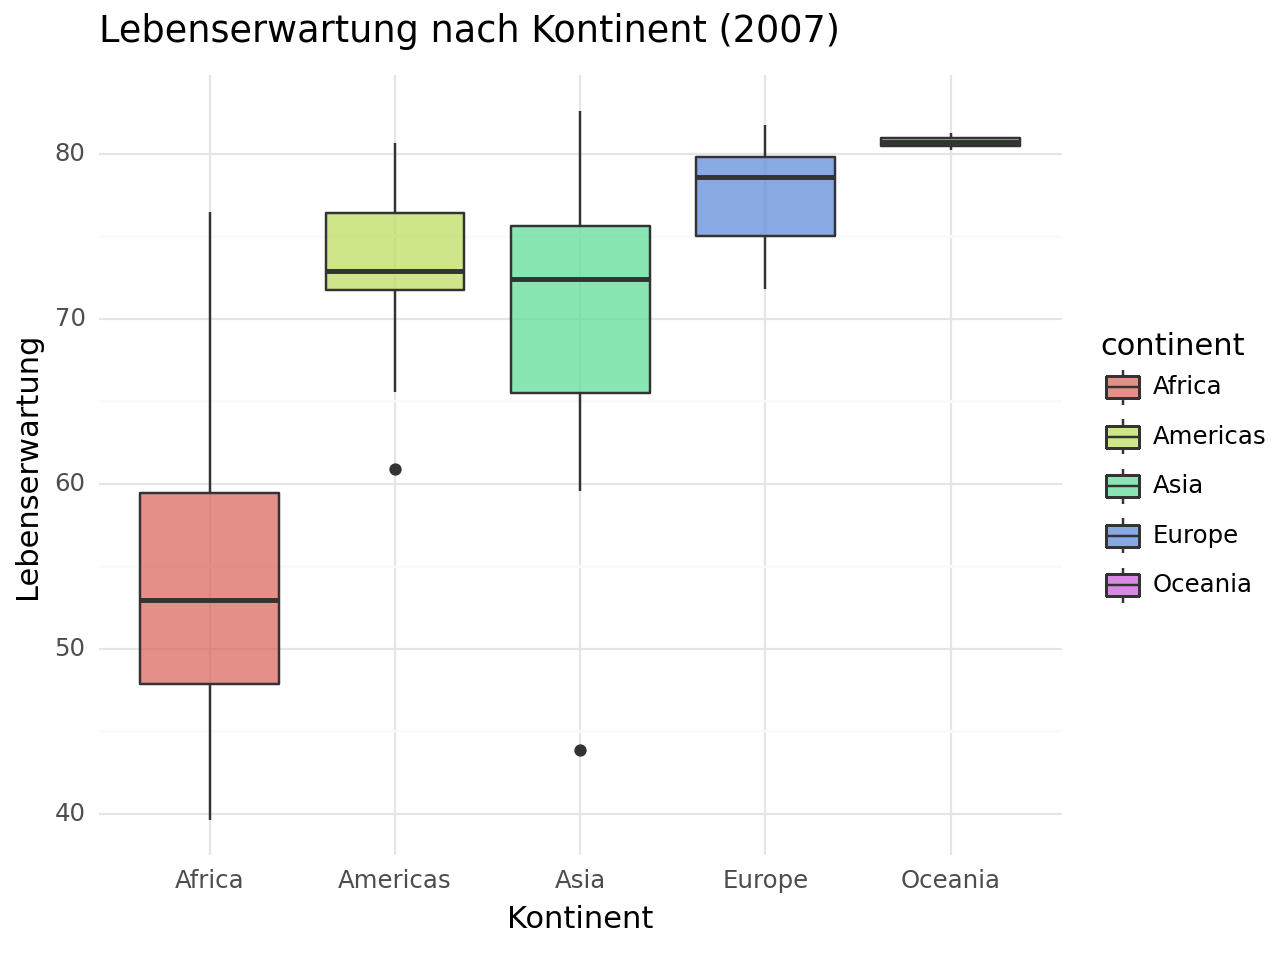

<Figure Size: (640 x 480)>

In [18]:
gap_2007 = gapminder[gapminder['year'] == 2007]

(ggplot(gap_2007, aes('continent', 'lifeExp', fill='continent'))
 + geom_boxplot(alpha=0.7)
 + theme_minimal()
 + labs(title='Lebenserwartung nach Kontinent (2007)',
        x='Kontinent', y='Lebenserwartung'))

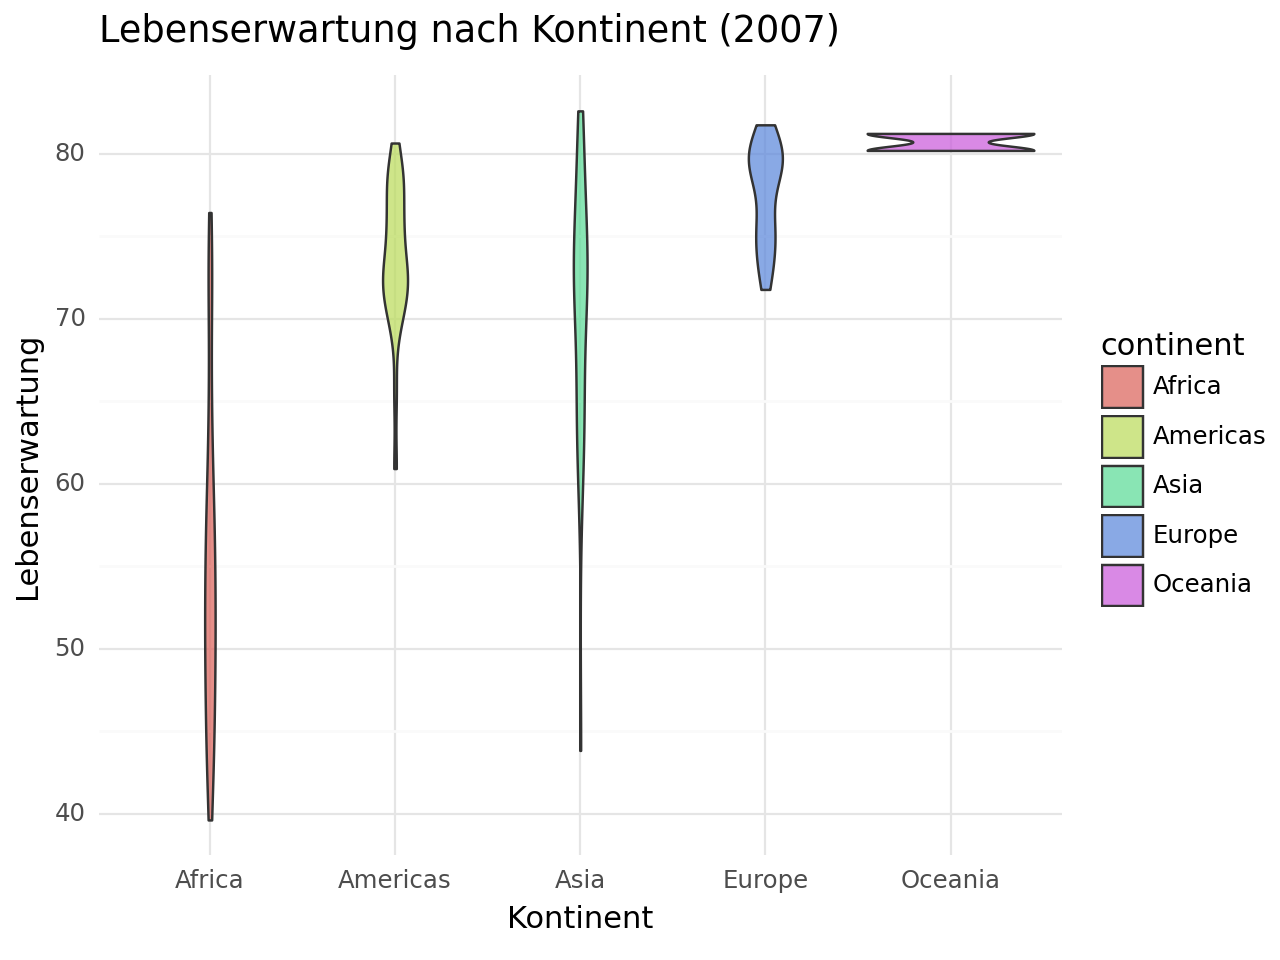

<Figure Size: (640 x 480)>

In [19]:
# Plot 2 violin plot (https://plotnine.org/reference/geom_violin.html)

gap_2007 = gapminder[gapminder['year'] == 2007]

(ggplot(gap_2007, aes('continent', 'lifeExp', fill='continent'))
 + geom_violin(alpha=0.7)
 + theme_minimal()
 + labs(title='Lebenserwartung nach Kontinent (2007)',
        x='Kontinent', y='Lebenserwartung'))

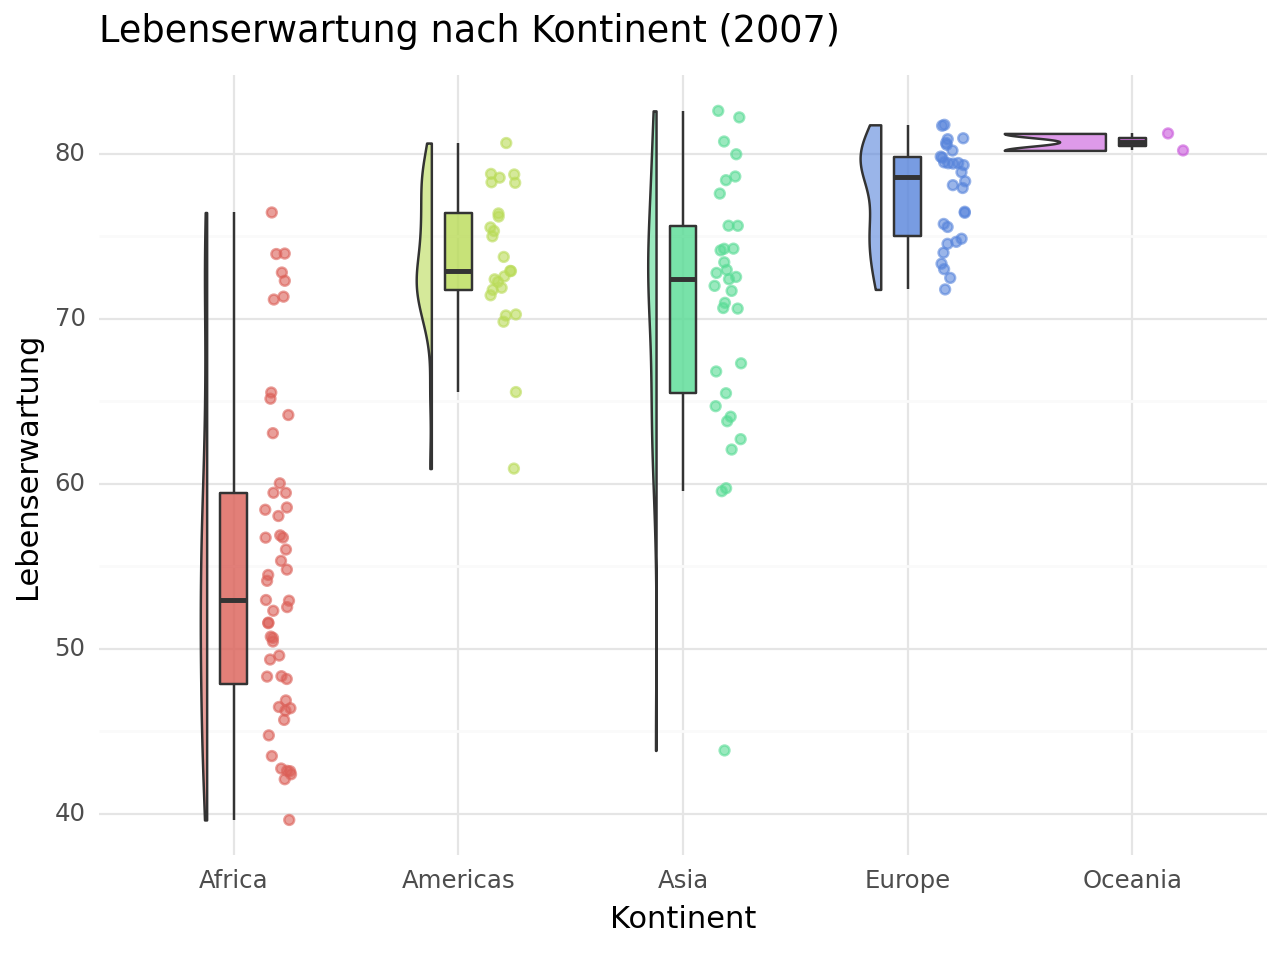

<Figure Size: (640 x 480)>

In [20]:
# Plot 3 - "raincloud" plot = boxplot + violinplot (https://r-charts.com/distribution/raincloud-plot/)

from plotnine import (
    ggplot, aes, geom_violin, geom_boxplot, geom_point,
    position_nudge, position_jitter, stage,
    theme_minimal, theme, labs
)

gap_2007 = gapminder[gapminder['year'] == 2007]

(ggplot(gap_2007, aes('continent', 'lifeExp', fill='continent'))
 + geom_violin(
     style='left', alpha=0.6,
     position=position_nudge(x=-0.12)
 )
 + geom_boxplot(
     width=0.12, alpha=0.8, outlier_shape=''
 )
 + geom_point(
     aes(x=stage('continent', after_scale='x + 0.2'),
         color='continent'),
     position=position_jitter(width=0.06, height=0, random_state=42),
     size=1.5, alpha=0.6
 )
 + theme_minimal()
 + theme(legend_position='none')
 + labs(title='Lebenserwartung nach Kontinent (2007)',
        x='Kontinent', y='Lebenserwartung'))

📈 Interpretation: Europa und Ozeanien liegen vorn, Afrika mit geringerer Lebenserwartung und größerer Streuung.

🧠 Didaktische Erklärung:
- geom_boxplot(): anderer Geom-Typ = anderer Informationsfokus → Verteilungen statt Einzelpunkte
- fill: Färbung der Flächen, unterscheidet sich von color (Umriss).
- Grammar of Graphics erlaubt, durch Geom-Wechsel völlig neue Fragen zu stellen.

# Aufgabe 3

Frage: Wie hat sich die Lebenserwartung der Länder (nach Kontinenten) über die Zeit verändert?

Ziel: Lernen, wie Facets Teilmengen der Daten trennen und Muster sichtbar machen.

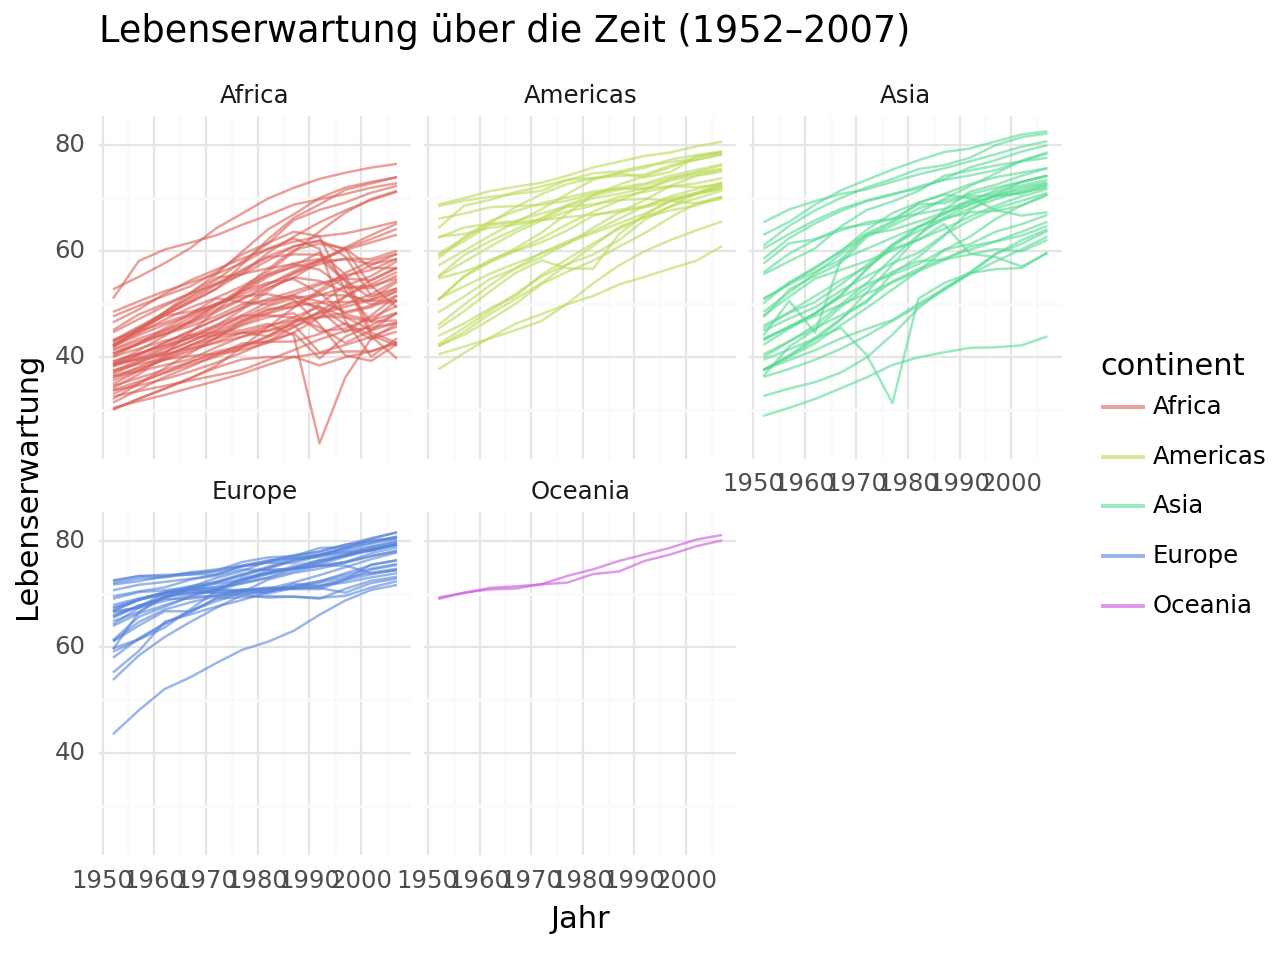

<Figure Size: (640 x 480)>

In [21]:
(
ggplot(gapminder, aes('year', 'lifeExp', group='country', color='continent'))
 + geom_line(alpha=0.6)
 + facet_wrap('~continent')
 + theme_minimal()
 + labs(title='Lebenserwartung über die Zeit (1952–2007)',
        x='Jahr', y='Lebenserwartung')
        )


📊 Interpretation: Alle Kontinente zeigen steigende Lebenserwartung, Afrika jedoch auf niedrigerem Niveau.

🧠 Didaktische Erklärung:

- geom_line(): verbindet Werte eines Landes → zeigt Trend.
- group: legt fest, dass Linien pro Land gezogen werden.
- facet_wrap(): unterteilt die Grafik nach Kategorien → mehrere kleine Diagramme mit gleichem Mapping.
- Facets = strukturierte Mehrfachdarstellungen — zeigen Vergleichbarkeit über Gruppen.

##### Frage: Was kann an dieser Visualisierung verbessert werden?

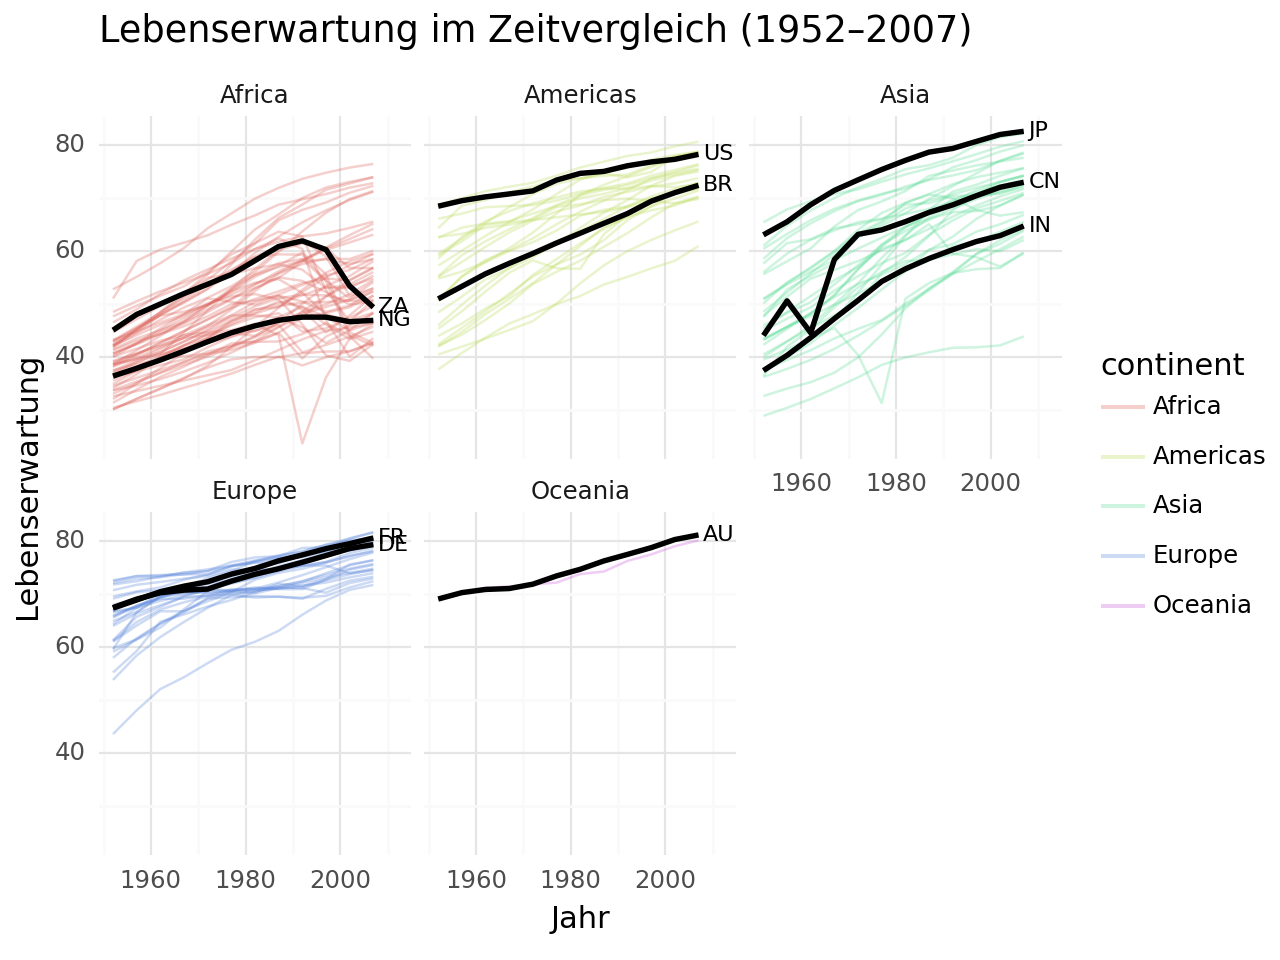

<Figure Size: (640 x 480)>

In [22]:
# Liste der hervorzuhebenden Länder und Ländercode-Mapping
highlight_countries = ['Germany', 'France', 'Japan', 'United States', 'Nigeria', 'India', "Australia", "Brazil", "China", "South Africa"]
country_codes = {'Germany': 'DE', 'France': 'FR', 'Japan': 'JP', 'United States': 'US', 'Nigeria': 'NG', 'India': 'IN', 'Australia': 'AU', 'Brazil': 'BR', 'China': 'CN', 'South Africa': 'ZA'}

highlight_data = gapminder[gapminder['country'].isin(highlight_countries)].copy()
highlight_2007 = highlight_data[highlight_data['year'] == 2007].copy()

# Neue Spalte mit Country-Codes
highlight_2007['code'] = highlight_2007['country'].map(country_codes)

p = (ggplot(gapminder, aes(x='year', y='lifeExp', group='country', color='continent'))
     + geom_line(alpha=0.3)
     + facet_wrap('~continent')
     + theme_minimal()
     + labs(title='Lebenserwartung im Zeitvergleich (1952–2007)',
            x='Jahr', y='Lebenserwartung'))

# Hervorhebung mehrerer Länder + Annotation mit Codes
p_highlight = (p
     + geom_line(
         mapping=aes(x='year', y='lifeExp', group='country'),
         data=highlight_data,
         color='black', size=1.1
       )
     + geom_text(
         mapping=aes(x='year', y='lifeExp', label='code'),
         data=highlight_2007,
         position=position_nudge(x=1),
         ha='left',
         color='black',
         size=8,
         show_legend=False
       )
     + scale_x_continuous(limits=[1952, 2012])
)

p_highlight

# Aufgabe 4

Frage: Wie verändern sich die globalen Muster von Wohlstand und Lebenserwartung über die Jahrzehnte hinweg? Sind die Unterschiede zwischen Kontinenten konstant, oder nähern sich Länder im Laufe der Zeit an?

Ziel: Verstehen, wie Änderungen von Zusammenhängen im Zeitverlauf visualisiert werden können – und wie man mit Facets mehrere Zeitabschnitte gleichzeitig visualisieren kann.

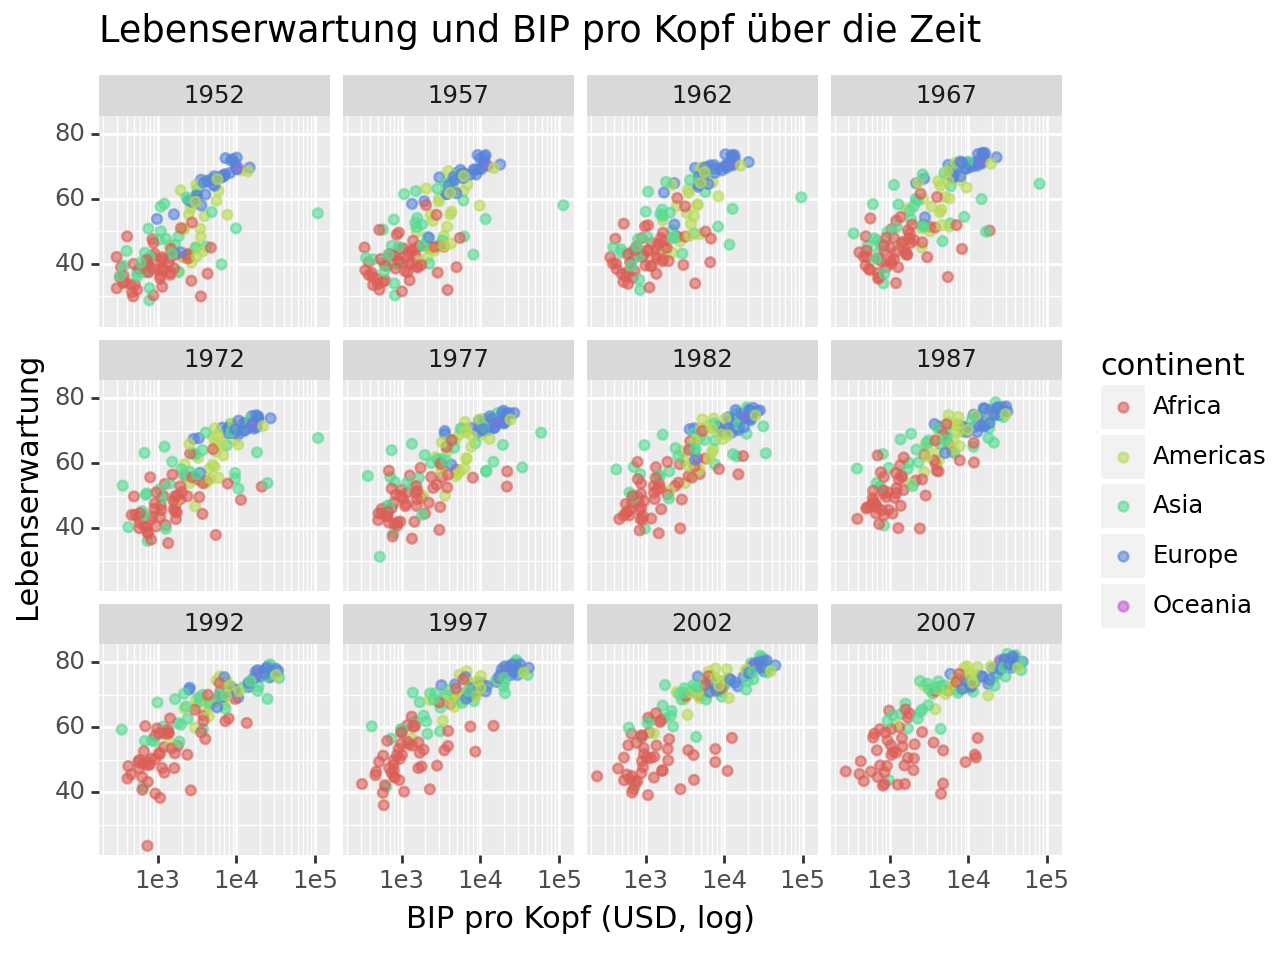

<Figure Size: (640 x 480)>

In [23]:
(ggplot(gapminder, aes('gdpPercap', 'lifeExp', color='continent'))
 + geom_point(alpha=0.6)
 + scale_x_log10()
 + facet_wrap('~year')
 + labs(title='Lebenserwartung und BIP pro Kopf über die Zeit',
        x='BIP pro Kopf (USD, log)',
        y='Lebenserwartung'))


📊 Interpretation der Ergebnisse
- Mit zunehmenden Jahren verschieben sich die Punkte nach rechts oben → Länder werden reicher und älter.
- Die Cluster der Kontinente wandern näher zusammen → globale Annäherung in Lebenserwartung.
- Afrika bleibt mit geringem Einkommen und niedriger Lebenserwartung zurück, zeigt aber Zuwächse.
- Faceting erlaubt eine visuelle Zeitreise durch Jahrzehnte — dieselben Mappings, aber verschiedene Teilmengen.

🧠 Didaktische Erklärung:
- `data`: legt die Datenquelle fest → Was wird gezeigt? → Beispiel: gapminder
- `aes()`: definiert das Mapping → Wie werden Daten visuell kodiert? → x = gdpPercap, y = lifeExp, color = continent
- `geom_point()`: bestimmt die Darstellungsform → Was wird gezeichnet? → Punkte für Länder im Streudiagramm
- `scale_x_log10()`: verändert die Skala → Wie wird der Wertebereich abgebildet? → Logarithmische Darstellung für bessere Vergleichbarkeit
- `facet_wrap('~year')`: teilt nach Gruppen → Wie werden Teilmengen gezeigt? → Ein Plot pro Jahr zur Zeitreihenanalyse
- `labs()`: ergänzt Kontext → Wie wird erklärt, was gezeigt wird? → Titel, Achsen, Legende
- `alpha = 0.6`: steuert Sichtbarkeit → Wie klar ist das Bild? → leichte Transparenz gegen Überlagerung

- Facets sind keine neue Art von Plot, sondern eine systematische Anwendung der gleichen Grammatik auf Teilmengen der Daten.
- Der Code zeigt, dass das “Baukastenprinzip” der Grammar of Graphics erweiterbar ist:
→ `data + aes + geom + scale + facet + theme + labels`
Besonders geeignet zur Demonstration des Konzepts „same grammar – multiple stories“.


# 5 Bonus: Themes 

Erstelle ein Liniendiagramm mit der Entwicklung Lebenserwartung für die 5 größten Europäischen Länder und nutze unterschiedliche Themes.  

### plotnine

Vorlage: https://plotnine.org/guide/themes-premade.html

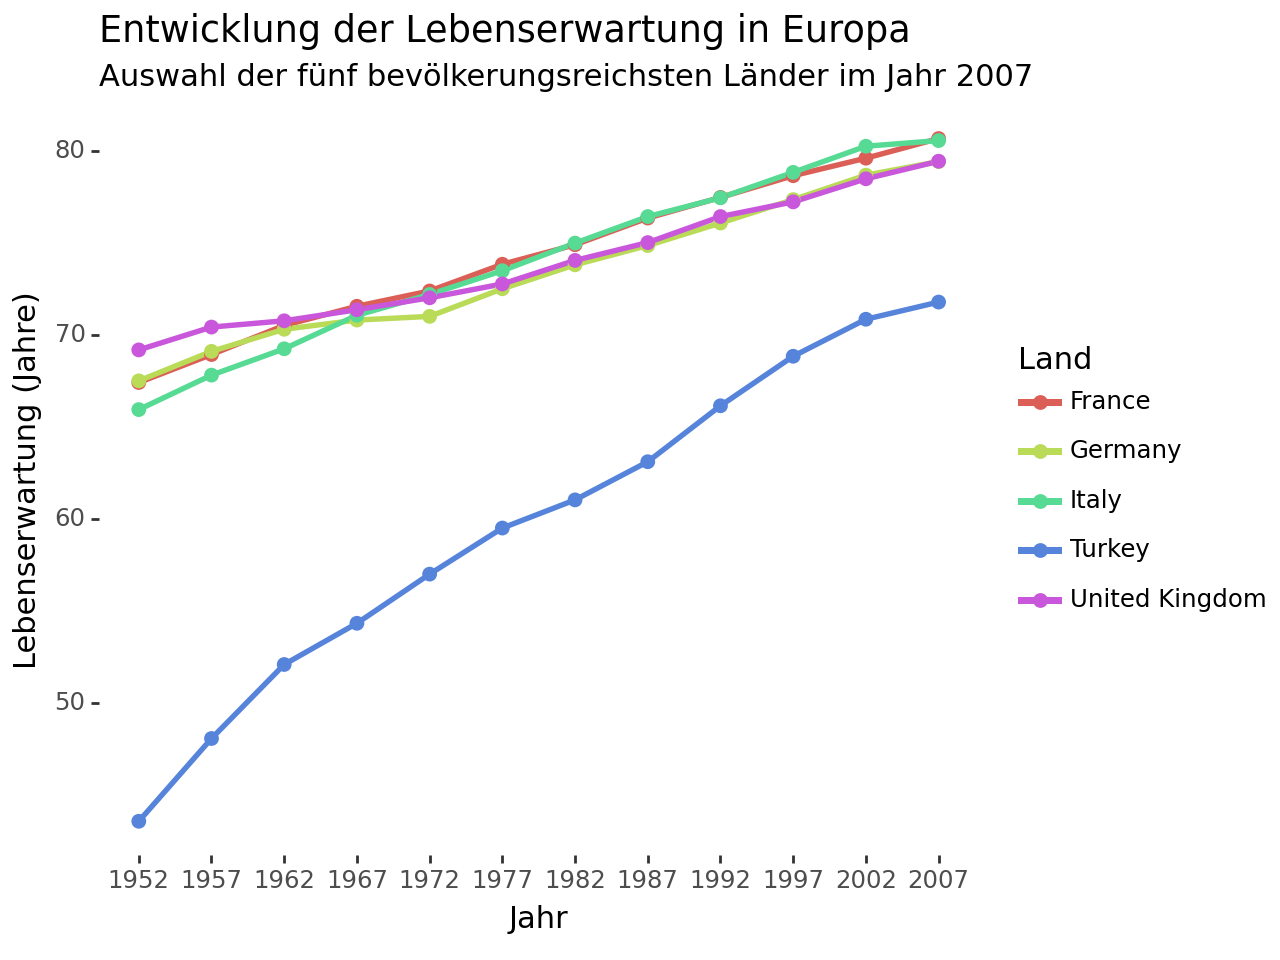

<Figure Size: (640 x 480)>

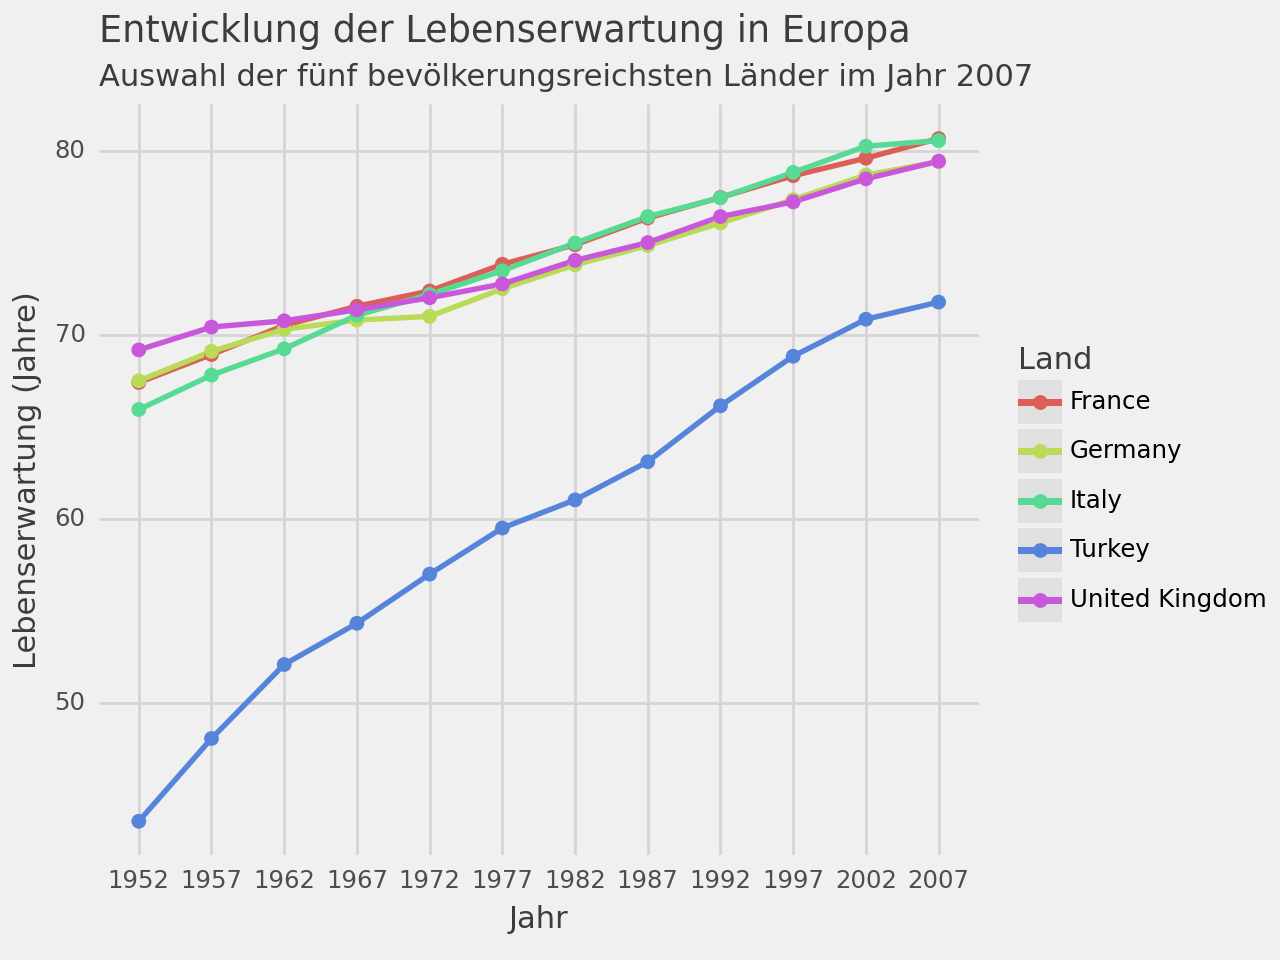

<Figure Size: (640 x 480)>

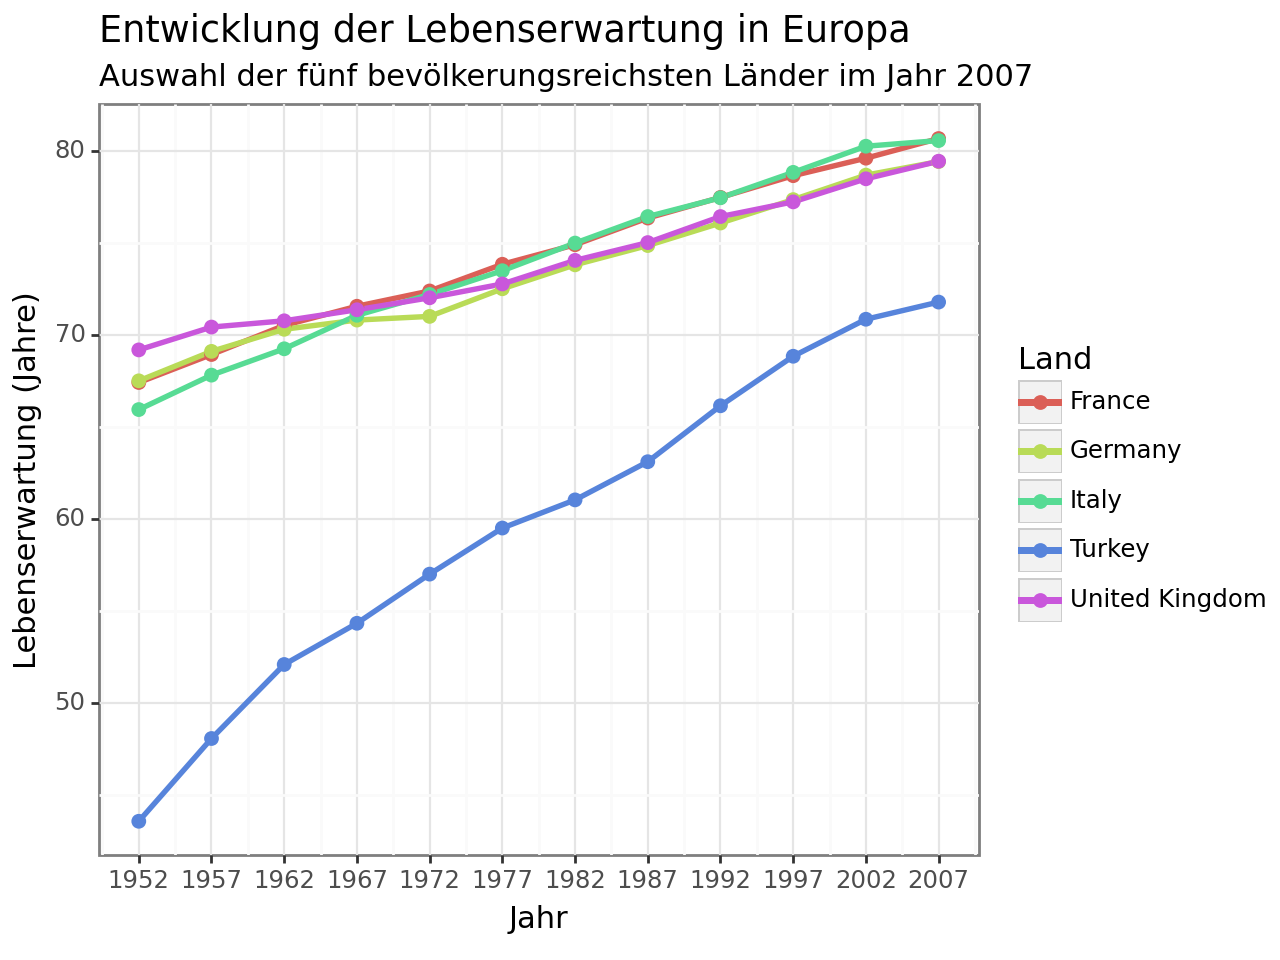

<Figure Size: (640 x 480)>

In [24]:
# Groesste Laender: hoechste Bevoelkerung im letzten Jahr des Gapminder-Datensatzes (2007)
europe_2007 = gapminder.query("continent == 'Europe' and year == 2007")
top_5_european_countries = europe_2007.nlargest(5, "pop")["country"].tolist()
top_5_europe = gapminder[gapminder["country"].isin(top_5_european_countries)].copy()

# Plot der Lebenserwartung der 5 bevölkerungsreichsten Länder Europas über die Zeit
base_plot = (
    ggplot(
        top_5_europe,
        aes(x="year", y="lifeExp", color="country", group="country"),
    )
    + geom_line(size=1.1)
    + geom_point(size=2)
    + scale_x_continuous(breaks=sorted(top_5_europe["year"].unique()))
    + labs(
        title="Entwicklung der Lebenserwartung in Europa",
        subtitle="Auswahl der fünf bevölkerungsreichsten Länder im Jahr 2007",
        x="Jahr",
        y="Lebenserwartung (Jahre)",
        color="Land",
    )
)

from IPython.display import display

display(base_plot + theme_tufte())
display(base_plot + theme_538())
display(base_plot + theme_bw())

### Economist Style (als matplotlib chart)

Vorlage: https://deepnote.com/app/radovankavicky/2022-07-01-Making-Economist-Style-Plots-in-Matplotlib-84f9c86d-1559-4654-b226-3dcff8be3408 

``` # Setup plot size.
fig, ax = plt.subplots(figsize=(8,4))

# Create grid 
# Zorder tells it which layer to put it on. We are setting this to 1 and our data to 2 so the grid is behind the data.
ax.grid(which="major", axis='y', color='#758D99', alpha=0.6, zorder=1)

# Plot data
# Loop through country names and plot each one.
for country in countries:
    ax.plot(gdp[gdp['country'] == country]['date'], 
            gdp[gdp['country'] == country]['gdp_trillions'], 
            color='#758D99', 
            alpha=0.8, 
            linewidth=3)

# Plot US and China separately
ax.plot(gdp[gdp['country'] == 'United States']['date'], 
        gdp[gdp['country'] == 'United States']['gdp_trillions'], 
        color='#006BA2',
        linewidth=3)

ax.plot(gdp[gdp['country'] == 'China']['date'], 
        gdp[gdp['country'] == 'China']['gdp_trillions'], 
        color='#3EBCD2',
        linewidth=3)

# Remove splines. Can be done one at a time or can slice with a list.
ax.spines[['top','right','left']].set_visible(False)

# Shrink y-lim to make plot a bit tigheter
ax.set_ylim(0, 23)

# Set xlim to fit data without going over plot area
ax.set_xlim(pd.datetime(1958, 1, 1), pd.datetime(2023, 1, 1))

# Reformat x-axis tick labels
ax.xaxis.set_tick_params(labelsize=11)        # Set tick label size

# Reformat y-axis tick labels
ax.set_yticklabels(np.arange(0,25,5),            # Set labels again
                   ha = 'right',                 # Set horizontal alignment to right
                   verticalalignment='bottom')   # Set vertical alignment to make labels on top of gridline      

ax.yaxis.set_tick_params(pad=-2,             # Pad tick labels so they don't go over y-axis
                         labeltop=True,      # Put x-axis labels on top
                         labelbottom=False,  # Set no x-axis labels on bottom
                         bottom=False,       # Set no ticks on bottom
                         labelsize=11)       # Set tick label size

# Add labels for USA and China
ax.text(x=.63, y=.67, s='United States', transform=fig.transFigure, size=10, alpha=.9)
ax.text(x=.7, y=.4, s='China', transform=fig.transFigure, size=10, alpha=.9)


# Add in line and tag
ax.plot([0.12, .9],                  # Set width of line
        [.98, .98],                  # Set height of line
        transform=fig.transFigure,   # Set location relative to plot
        clip_on=False, 
        color='#E3120B', 
        linewidth=.6)
ax.add_patch(plt.Rectangle((0.12,.98),                 # Set location of rectangle by lower left corder
                           0.04,                       # Width of rectangle
                           -0.02,                      # Height of rectangle. Negative so it goes down.
                           facecolor='#E3120B', 
                           transform=fig.transFigure, 
                           clip_on=False, 
                           linewidth = 0))

# Add in title and subtitle
ax.text(x=0.12, y=.91, s="Ahead of the pack", transform=fig.transFigure, ha='left', fontsize=13, weight='bold', alpha=.8)
ax.text(x=0.12, y=.86, s="Top 9 GDP's by country, in trillions of USD, 1960-2020", transform=fig.transFigure, ha='left', fontsize=11, alpha=.8)

# Set source text
ax.text(x=0.12, y=0.01, s="""Source: "GDP of all countries(1960-2020)" via Kaggle.com""", transform=fig.transFigure, ha='left', fontsize=9, alpha=.7)

# Export plot as high resolution PNG
plt.savefig('images/economist_line.png',    # Set path and filename
            dpi = 300,                     # Set dots per inch
            bbox_inches="tight",           # Remove extra whitespace around plot
            facecolor='white')             # Set background color to white
```

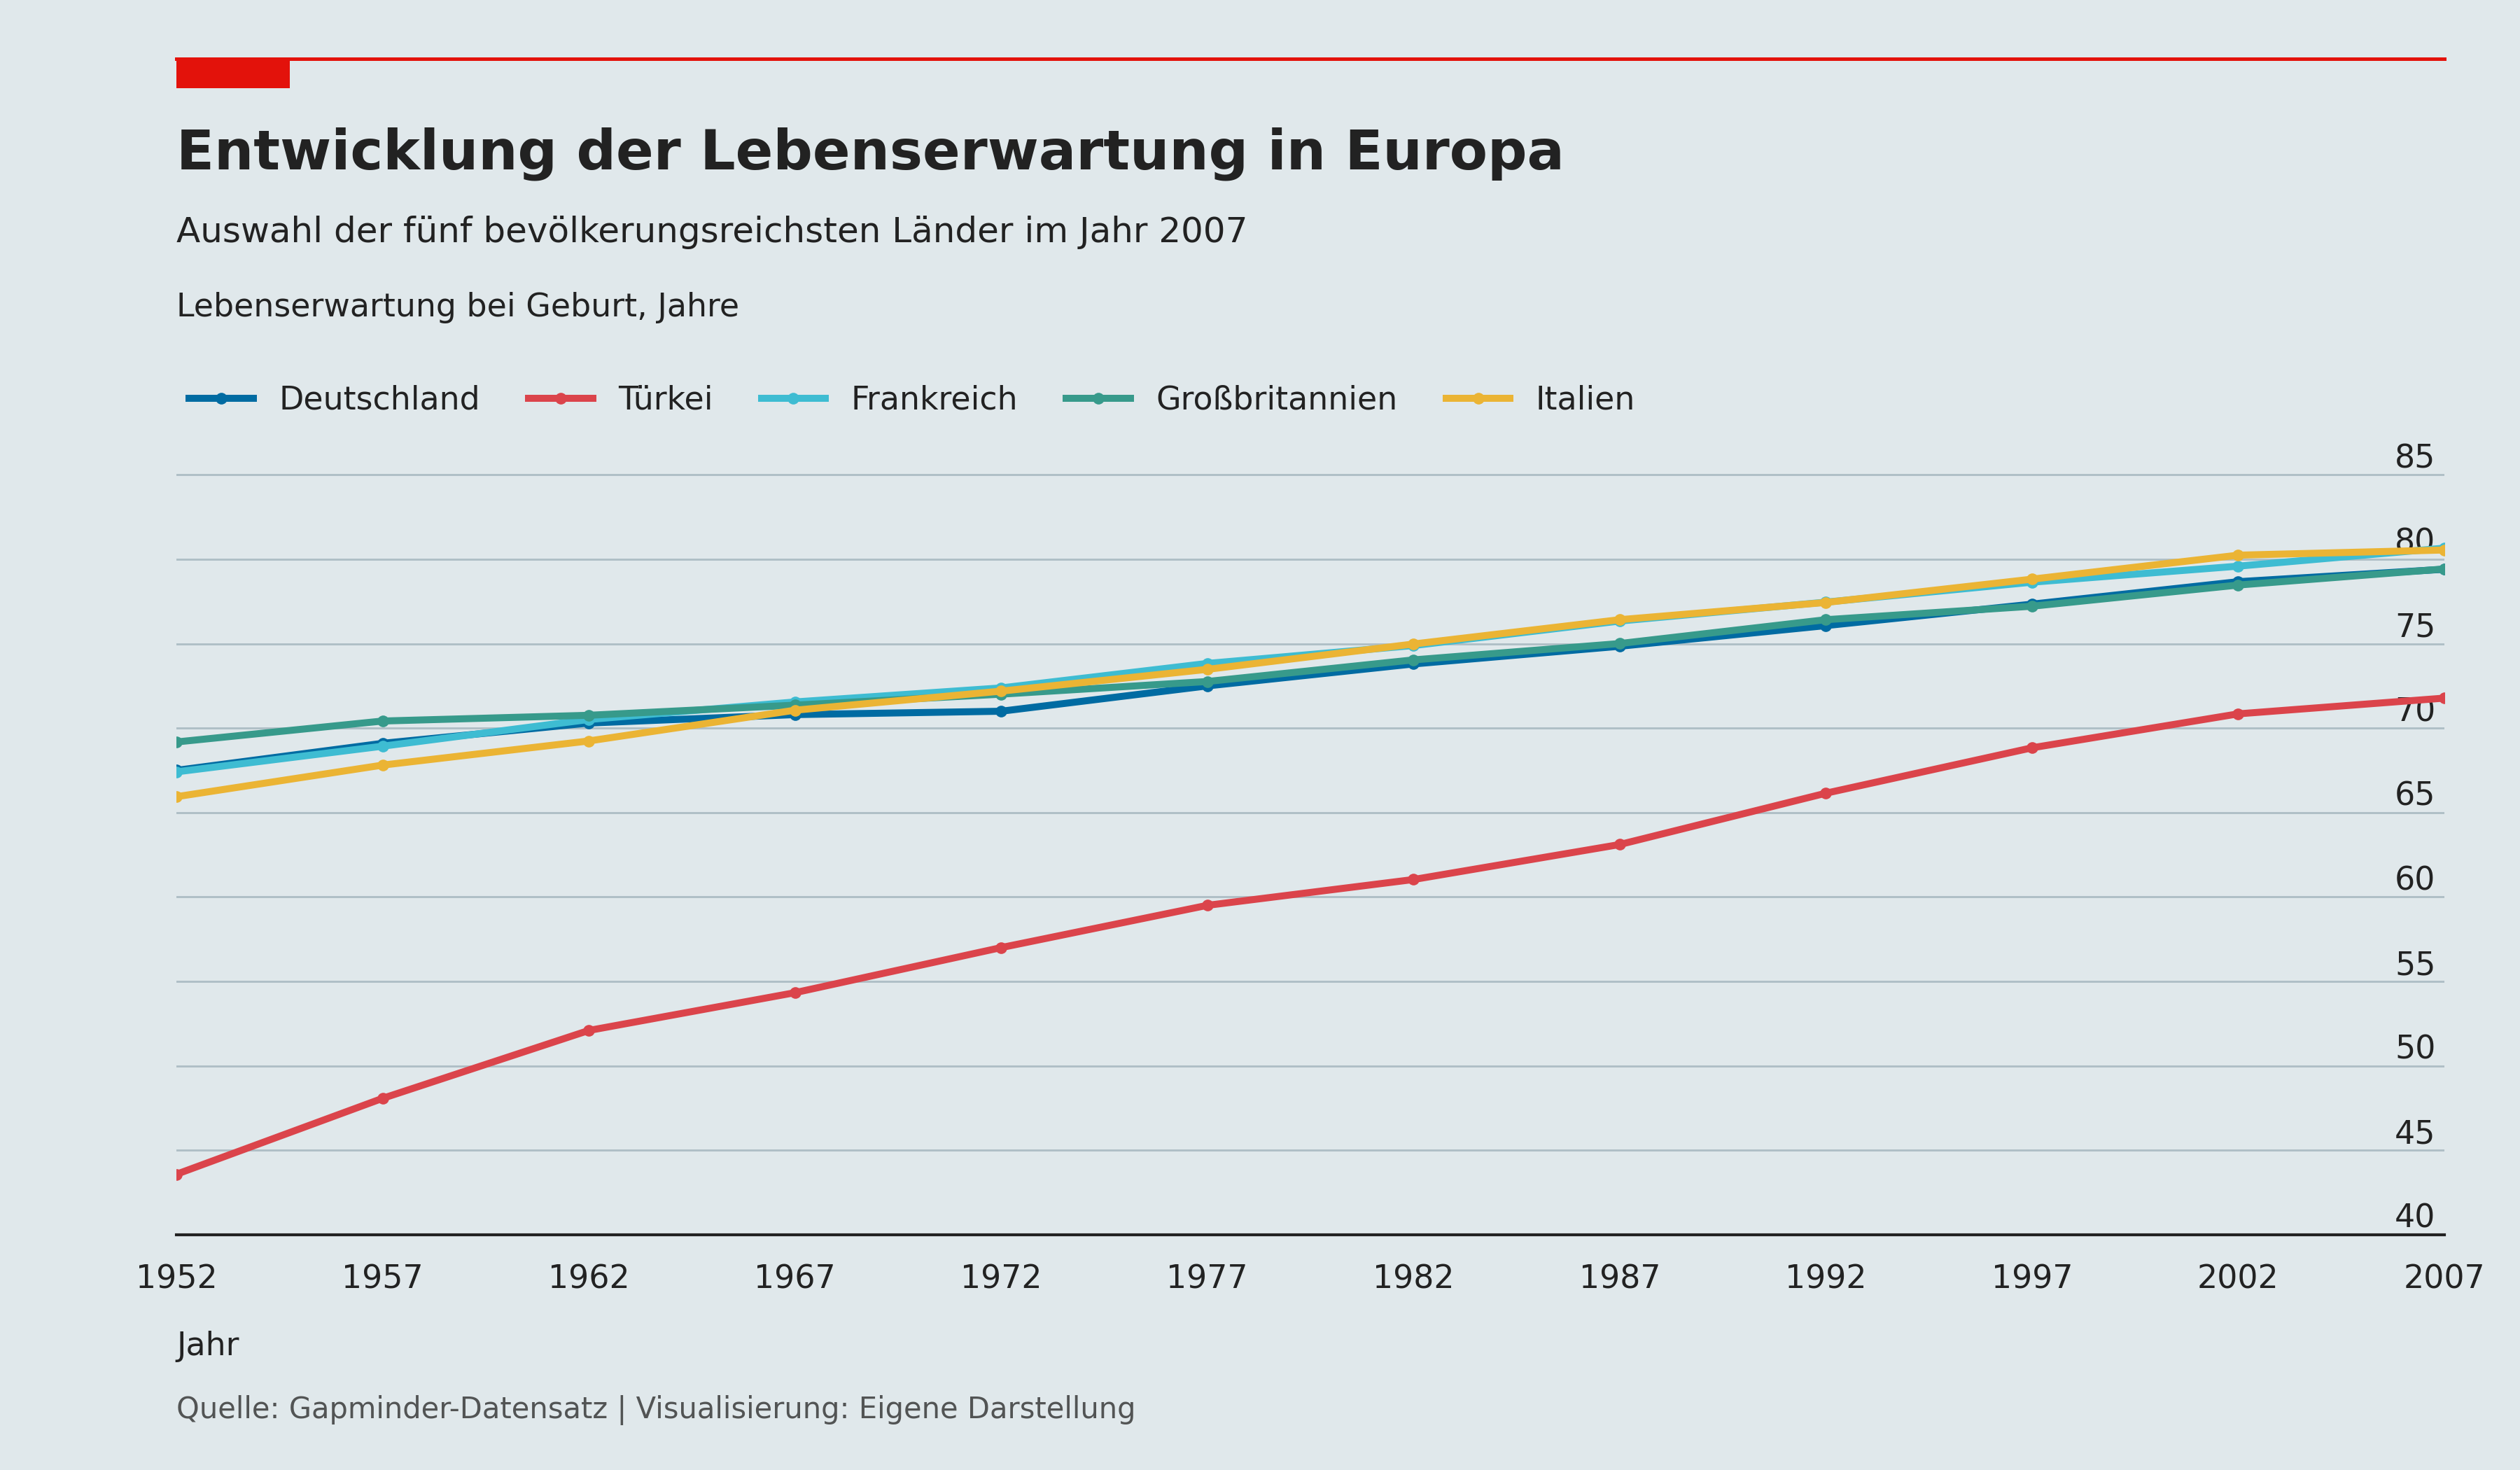

In [25]:
# Import matplotlib für die Visualisierung
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

# Voraussetzung: gapminder ist ein pandas-DataFrame mit den Spalten
# country, continent, year, pop und lifeExp.

# Die fünf bevölkerungsreichsten Länder Europas im Jahr 2007
europe_2007 = gapminder.query("continent == 'Europe' and year == 2007")
countries = europe_2007.nlargest(5, "pop")["country"].tolist()

data = (
    gapminder.loc[gapminder["country"].isin(countries)]
    .copy()
    .sort_values(["country", "year"])
)

# Economist-Farben
ECON_RED = "#E3120B"
BACKGROUND = "#E0E8EB"  # Näherung des hellblauen Print-Hintergrunds
GRID = "#758D99"
COLORS = ["#006BA2", "#DB444B", "#3EBCD2", "#379A8B", "#EBB434"]

country_names = {
    "Germany": "Deutschland",
    "United Kingdom": "Großbritannien",
    "France": "Frankreich",
    "Turkey": "Türkei",
    "Italy": "Italien",
}

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "text.color": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "figure.facecolor": BACKGROUND,
    "axes.facecolor": BACKGROUND,
    "savefig.facecolor": BACKGROUND,
}):
    fig, ax = plt.subplots(figsize=(12, 7), dpi=150)
    fig.subplots_adjust(left=0.07, right=0.97, bottom=0.16, top=0.70)

    # Zeitreihen zeichnen
    for country, color in zip(countries, COLORS):
        series = data.loc[data["country"].eq(country)]

        ax.plot(
            series["year"],
            series["lifeExp"],
            color=color,
            linewidth=2.4,
            marker="o",
            markersize=4,
            markeredgewidth=0,
            label=country_names.get(country, country),
            zorder=3,
        )

    # Nur horizontale Hauptgitternetzlinien
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, color=GRID, linewidth=0.7, alpha=0.45)
    ax.xaxis.grid(False)
    ax.minorticks_off()

    # Nur die untere Achsenlinie anzeigen
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_color("#222222")
    ax.spines["bottom"].set_linewidth(1)

    # X-Achse: alle Erhebungsjahre
    years = sorted(data["year"].unique())
    ax.set_xticks(years)
    ax.set_xlim(min(years), max(years))
    ax.tick_params(axis="x", length=0, pad=10)
    ax.set_xlabel("Jahr", loc="left", labelpad=12)

    # Y-Achse: Fünfjahresschritte
    lower = 5 * np.floor(data["lifeExp"].min() / 5)
    upper = 5 * np.ceil(data["lifeExp"].max() / 5)

    ax.set_ylim(lower, upper + 2)
    ax.set_yticks(np.arange(lower, upper + 1, 5))
    ax.set_ylabel("")

    # Zahlen rechts innerhalb der Zeichenfläche,
    # jeweils knapp oberhalb der Gitternetzlinien
    ax.yaxis.tick_right()
    ax.tick_params(axis="y", length=0, pad=-3)

    for label in ax.get_yticklabels():
        label.set_horizontalalignment("right")
        label.set_verticalalignment("bottom")

    # Titel und Untertitel
    fig.text(
        0.07, 0.885,
        "Entwicklung der Lebenserwartung in Europa",
        fontsize=19,
        fontweight="bold",
        ha="left",
    )
    fig.text(
        0.07, 0.835,
        "Auswahl der fünf bevölkerungsreichsten Länder im Jahr 2007",
        fontsize=12,
        ha="left",
    )
    fig.text(
        0.07, 0.785,
        "Lebenserwartung bei Geburt, Jahre",
        fontsize=11,
        ha="left",
    )

    # Legende oberhalb der Zeichenfläche
    ax.legend(
        loc="lower left",
        bbox_to_anchor=(0, 1.015),
        ncol=5,
        frameon=False,
        borderaxespad=0,
        handlelength=2,
        columnspacing=1.5,
    )

    # Rote Kopfzeile
    fig.add_artist(Line2D(
        [0.07, 0.97], [0.96, 0.96],
        transform=fig.transFigure,
        color=ECON_RED,
        linewidth=1.2,
    ))

    # Roter Economist-Tag
    fig.add_artist(Rectangle(
        (0.07, 0.94),
        width=0.045,
        height=0.02,
        transform=fig.transFigure,
        facecolor=ECON_RED,
        edgecolor="none",
    ))

    # Quellenangabe
    fig.text(
        0.07, 0.035,
        "Quelle: Gapminder-Datensatz | Visualisierung: Eigene Darstellung",
        fontsize=10,
        alpha=0.75,
        ha="left",
    )

    # Optional speichern:
    # fig.savefig(
    #     "lebenserwartung_economist.png",
    #     dpi=300,
    #     bbox_inches="tight",
    #     facecolor=fig.get_facecolor(),
    # )

    plt.show()